<p class="lead">Frequentist statistics answers "how surprising would these data be if nothing were going on?". Bayesian statistics answers the question researchers actually ask — "given these data, what should I now believe?" — at the price of having to say what you believed beforehand. This unit is the one place in the course where that price is paid explicitly, and it is worth paying whenever the data are small, nested, or arriving one experiment at a time: a thesis project with three replicas, a compound measured in two assays, a screening campaign whose hit rate must be estimated after forty tested molecules. We build the machinery from arithmetic upwards — Bayes' theorem on natural frequencies, conjugate updating by hand, grid approximation, and a Markov chain Monte Carlo sampler written from scratch in fifteen lines — and apply it to two problems the laboratory meets constantly: <strong>what is the probability that a predicted hit is really active</strong>, and <strong>how should potencies measured in 108 different assays be combined</strong>. The second question introduces partial pooling, the single most useful idea in this unit.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad (optativa, recomendada para proyectos con datos escasos o con estructura jerárquica) presenta el razonamiento bayesiano. Se enuncia el teorema de Bayes en palabras y se aplica a la falacia de la tasa base: dada una prevalencia y un factor de enriquecimiento, ¿cuál es la probabilidad de que un "hit" computacional sea realmente activo? Se realiza la actualización conjugada beta-binomial a mano, la aproximación por malla y un muestreador de Metropolis escrito desde cero, con diagnósticos de convergencia (trazas, R-hat, tamaño efectivo de muestra). Se ajusta un modelo jerárquico de la potencia frente a ROCK1 en 108 ensayos que muestra el encogimiento (shrinkage) de las medias de los ensayos pequeños hacia la media global, y se realizan comprobaciones predictivas previas y posteriores. Finalmente se comparan intervalos creíbles e intervalos de confianza sobre los mismos datos. <b>Nota:</b> PyMC se instala en el entorno del curso pero su compilador no funciona en la máquina de compilación, por lo que todos los modelos se implementan a mano; el código equivalente en PyMC se incluye como texto para ejecutarlo en Colab.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>State Bayes' theorem in words and apply it to diagnostic-test and virtual-screening scenarios, including the base-rate fallacy.</li>
<li>Build and interpret simple Bayesian models — beta–binomial, normal with unknown mean — and read a posterior and a credible interval.</li>
<li>Compute a posterior three ways: conjugate algebra, grid approximation and Markov chain Monte Carlo.</li>
<li>Write a Metropolis sampler from scratch and diagnose it with trace plots, acceptance rate, R-hat and effective sample size.</li>
<li>Explain hierarchical (partial-pooling) models, why they suit compounds nested in assays or frames nested in replicas, and what shrinkage does.</li>
<li>Run prior and posterior predictive checks and justify a prior to a referee.</li>
<li>State the difference between a credible interval and a confidence interval, and when the two coincide.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read linearly, running each cell; then change a prior and re-run, which is the fastest way to develop intuition for how much the prior actually matters. Everything here runs on NumPy<sup class="c"><a href="#r1">[1]</a></sup>, SciPy<sup class="c"><a href="#r2">[2]</a></sup>, pandas and Matplotlib plus RDKit for the screening example (in Colab run <code>!pip install rdkit</code> once before the setup cell). <b>No probabilistic-programming library is required:</b> every model is implemented explicitly, which is the teaching point, and §9 gives the equivalent PyMC code for readers who want it. This unit is marked <em>extended</em>: it assumes <a href="../U7_Estimation/index.html">Unit 7</a> and <a href="../U8_Hypothesis_Testing/index.html">Unit 8</a>, and it pairs with <a href="../U9_Linear_Models/index.html">Unit 9</a>, whose mixed-effects models are the frequentist siblings of §7.</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit
from pathlib import Path
import urllib.request
import numpy as np, pandas as pd, scipy, matplotlib, matplotlib.pyplot as plt
from scipy import stats
np.random.seed(0)
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | pandas 3.0.3 | scipy 1.17.1 | matplotlib 3.11.0


## 1. Bayes' theorem in words

For a hypothesis $H$ and data $D$,

$$\underbrace{P(H\mid D)}_{\text{posterior}} = \frac{\overbrace{P(D\mid H)}^{\text{likelihood}}\;\overbrace{P(H)}^{\text{prior}}}{\underbrace{P(D)}_{\text{evidence}}},$$

which in words is: **what you should believe after seeing the data is what the data say about each hypothesis, weighted by what you believed before, renormalised**. The denominator is just the sum of the numerator over all hypotheses, so it rarely needs separate attention.

Three consequences are worth internalising before any computation:

1. **The likelihood alone is not enough.** $P(D\mid H)$ and $P(H\mid D)$ are different quantities, and confusing them is the formal content of the base-rate fallacy (§2) and of the commonest misreading of a p-value<sup class="c"><a href="#r3">[3]</a></sup><sup class="c"><a href="#r4">[4]</a></sup>.
2. **The prior is an assumption, like every other modelling choice**, and it must be stated, justified and varied in a sensitivity analysis (§5). A model with no prior is not assumption-free; it has made a hidden one.
3. **The output is a distribution, not a number.** Everything a Bayesian analysis reports — a point estimate, an interval, a probability that one series is more potent than another — is a summary of that distribution.

<div class="box bridge"><h4>Domain context — virtual screening, prevalence and enrichment</h4>
<p>A <strong>virtual screen</strong> ranks a large library of purchasable molecules with a computational score and sends the top fraction — typically the best 0.1 % to 1 % — for experimental testing. Two numbers describe how well it worked. The <strong>prevalence</strong> (or base rate) is the proportion of genuinely active molecules in the library; for a real vendor catalogue screened against one target it is of the order of 0.01 % to 1 %. The <strong>enrichment factor</strong> at x %, EF<sub>x%</sub>, is the hit rate among the selected top x % divided by the prevalence: an EF of 10 means the screen found ten times more actives than picking at random would have<sup class="c"><a href="#r5">[5]</a></sup>. Note the ceiling: EF cannot exceed 1/prevalence, since the hit rate cannot exceed 1. The <strong>decoys</strong> used to measure enrichment in a benchmark are molecules presumed inactive, and how they were chosen changes every number<sup class="c"><a href="#r6">[6]</a></sup> — the subject of Unit 19. The quantity a medicinal chemist actually needs is none of these: it is the probability that a molecule the computer selected will turn out to be active, which is a posterior probability and is computed below.</p></div>

## 2. The base-rate fallacy, with natural frequencies

The classic demonstration is medical. A disease affects 1 in 1,000 people. A test detects 99 % of cases and gives a false positive in 5 % of healthy people. Your test is positive. What is the probability that you are ill?

The intuitive answer is "about 95 %". The correct answer is obtained by counting people rather than manipulating probabilities<sup class="c"><a href="#r7">[7]</a></sup>:

| | ill | healthy | total |
|---|---|---|---|
| **test positive** | 99 | 4,995 | 5,094 |
| **test negative** | 1 | 94,905 | 94,906 |
| **total** | 100 | 99,900 | 100,000 |

Of 100,000 people, 100 are ill; the test finds 99 of them. Of the 99,900 healthy people, 5 % — 4,995 — also test positive. So among the 5,094 positive tests only 99 are genuinely ill: **P(ill | positive) = 99/5,094 ≈ 1.9 %**. The test is excellent and the posterior is still under 2 %, because the prior was 0.1 %. Physicians asked this question answer it wrongly at a famously high rate<sup class="c"><a href="#r8">[8]</a></sup>.

The virtual-screening problem has exactly the same arithmetic, with prevalence in place of disease frequency and the enrichment factor in place of sensitivity and specificity. If selecting the top x % of a library enriches actives by a factor EF, then by definition

$$P(\text{active}\mid\text{selected}) = \mathrm{EF}_{x\%}\times \text{prevalence}.$$

               ill  healthy  total
test positive   99     4995   5094
test negative    1    94905  94906
P(ill | positive) = 99 / 5094 = 0.0194  (1.9 %)



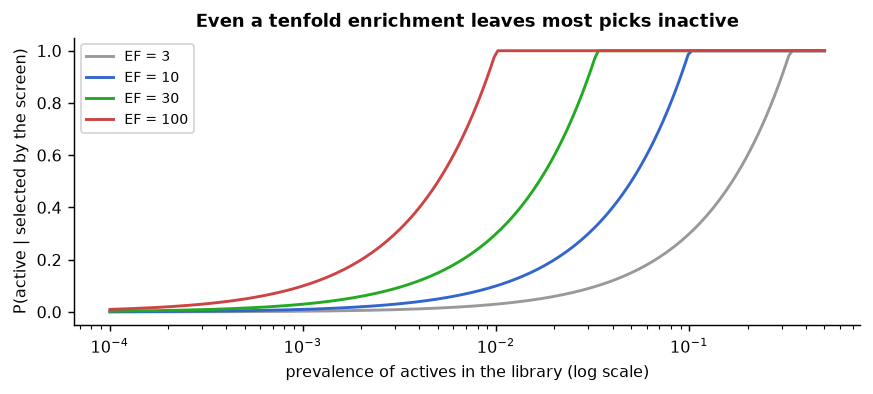

,prevalence,EF,P(active | selected),actives among 100 compounds tested
scenario,,,,
"focused library, strong model",0.200,3,0.60,60.0
curated subset,0.010,10,0.10,10.0
vendor catalogue,0.001,10,0.01,1.0
"vendor catalogue, excellent model",0.001,100,0.10,10.0


In [2]:
# The medical table and the screening table, computed, and the general curve.
N, prev_med, sens, fpr = 100_000, 0.001, 0.99, 0.05
ill = N * prev_med
tab = pd.DataFrame({"ill": [ill * sens, ill * (1 - sens)],
                    "healthy": [(N - ill) * fpr, (N - ill) * (1 - fpr)]},
                   index=["test positive", "test negative"]).astype(int)
tab["total"] = tab.sum(axis=1)
ppv = tab.loc["test positive", "ill"] / tab.loc["test positive", "total"]
print(tab.to_string())
print("P(ill | positive) = %d / %d = %.4f  (%.1f %%)\n"
      % (tab.loc['test positive', 'ill'], tab.loc['test positive', 'total'], ppv, 100 * ppv))

prevs = np.logspace(-4, -0.3, 200)
fig, ax = plt.subplots(figsize=(6.8, 3.1))
for ef, c in [(3, "#999"), (10, "#36c"), (30, "#2a2"), (100, "#c44")]:
    ax.plot(prevs, np.minimum(1.0, ef * prevs), color=c, lw=1.6, label="EF = %d" % ef)
ax.set_xscale("log"); ax.set_xlabel("prevalence of actives in the library (log scale)")
ax.set_ylabel("P(active | selected by the screen)")
ax.set_title("Even a tenfold enrichment leaves most picks inactive"); ax.legend(fontsize=7.5)
fig.tight_layout()
rows = [{"scenario": s, "prevalence": p, "EF": e, "P(active | selected)": min(1.0, p * e),
         "actives among 100 compounds tested": round(100 * min(1.0, p * e), 1)}
        for s, p, e in [("focused library, strong model", 0.20, 3),
                        ("curated subset", 0.01, 10),
                        ("vendor catalogue", 0.001, 10),
                        ("vendor catalogue, excellent model", 0.001, 100)]]
pd.DataFrame(rows).set_index("scenario").round(4)

<p class="caption"><b>Figure 1.</b> Posterior probability that a selected molecule is active, as a function of the library's prevalence of actives, for four enrichment factors. The curves are straight lines on these axes because the posterior is simply EF × prevalence until it saturates at 1. At a realistic catalogue prevalence of 0.1 %, even an enrichment factor of 10 gives a 1 % chance that any individual pick is active — one hit per hundred compounds ordered — and an enrichment of 100, which would be an outstanding result, gives one in ten. The table below the figure converts the same arithmetic into compounds ordered.</p>

This single calculation explains several things students find puzzling. It explains why experimental groups ask for 50–100 compounds from a virtual screen rather than 5: at a 1–10 % expected hit rate, ordering five compounds has a substantial chance of returning nothing. It explains why benchmark enrichment factors are optimistic: a benchmark set has a prevalence of a few per cent by construction (ours is about 11 %), hundreds of times higher than a real catalogue. And it is structurally the same calculation as the positive predictive value of a significant p-value<sup class="c"><a href="#r4">[4]</a></sup><sup class="c"><a href="#r3">[3]</a></sup>: a "significant" result from a field in which few hypotheses are true is mostly a false positive, for exactly the reason the medical table above is mostly false positives.

In [3]:
# The enrichment factor of a real ligand-based ranking, and its ceiling.
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")
lib = load_data("screening_library.csv")
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in lib["std_smiles"]]
act_idx = np.where(lib["label"].to_numpy() == 1)[0]
ref = np.random.default_rng(0).choice(act_idx, 25, replace=False)
keep = np.ones(len(lib), bool); keep[ref] = False
score = np.array([max(DataStructs.BulkTanimotoSimilarity(fps[i], [fps[j] for j in ref]))
                  for i in range(len(lib))])
s_lib, y_lib = score[keep], lib["label"].to_numpy()[keep]
prev_bench = y_lib.mean()
print("benchmark prevalence of actives: %.3f  -> maximum possible EF = 1/prevalence = %.1f"
      % (prev_bench, 1 / prev_bench))
for frac in (0.01, 0.05, 0.10, 0.20):
    k = int(frac * len(s_lib)); top = np.argsort(-s_lib)[:k]
    print("  top %5.1f %% : hit rate %.3f -> EF = %.2f" % (100 * frac, y_lib[top].mean(),
                                                           y_lib[top].mean() / prev_bench))
ef10 = (y_lib[np.argsort(-s_lib)[:int(0.10 * len(s_lib))]].mean()) / prev_bench
for prev_real in (0.10, 0.01, 0.001):
    print("if the real library had prevalence %.3f, this EF%.1f would give P(active|pick) = %.4f"
          % (prev_real, ef10, min(1.0, ef10 * prev_real)))

benchmark prevalence of actives: 0.109  -> maximum possible EF = 1/prevalence = 9.2
  top   1.0 % : hit rate 1.000 -> EF = 9.21
  top   5.0 % : hit rate 1.000 -> EF = 9.21
  top  10.0 % : hit rate 0.819 -> EF = 7.54
  top  20.0 % : hit rate 0.461 -> EF = 4.24
if the real library had prevalence 0.100, this EF7.5 would give P(active|pick) = 0.7544
if the real library had prevalence 0.010, this EF7.5 would give P(active|pick) = 0.0754
if the real library had prevalence 0.001, this EF7.5 would give P(active|pick) = 0.0075


The ranking is genuinely good — at the top 1 % every selected molecule is an active, which is the maximum the benchmark allows, since the enrichment factor is capped at 1/prevalence ≈ 9.2. That cap is the first thing to check when reading an enrichment number in a paper: an EF of 9 on a benchmark with 11 % actives is a *perfect* result, while an EF of 9 on a catalogue with 0.1 % actives still means 99 of every 100 ordered compounds are inactive.

## 3. The beta–binomial, by hand

The simplest real Bayesian model: we test $n$ compounds from a screen, $k$ turn out active, and we want the posterior for the hit rate $\theta$.

- **Likelihood**: $P(k \mid \theta) \propto \theta^{k}(1-\theta)^{n-k}$ — the binomial.
- **Prior**: $\theta \sim \text{Beta}(a, b)$, whose density is proportional to $\theta^{a-1}(1-\theta)^{b-1}$. Beta(1,1) is uniform; Beta(2,18) has mean 0.1 and is the sort of weakly informative prior a chemist's experience justifies.
- **Posterior**: multiplying, $\theta \mid k \sim \text{Beta}(a+k,\; b+n-k)$. The prior is **conjugate**: the posterior is in the same family, and updating is addition.

### Worked example

Prior Beta(2, 18) — "we expect about 10 % hits, with the confidence of about 20 prior observations". We test **40** compounds and **6** are active.

Posterior = Beta(2 + 6, 18 + 40 − 6) = **Beta(8, 52)**.

| quantity | formula | value |
|---|---|---|
| prior mean | a/(a+b) = 2/20 | 0.1000 |
| maximum-likelihood estimate | k/n = 6/40 | 0.1500 |
| posterior mean | 8/(8+52) | **0.1333** |
| posterior mode | (8−1)/(8+52−2) = 7/58 | 0.1207 |
| posterior SD | √(ab/((a+b)²(a+b+1))) with a=8, b=52 | 0.0435 |

The posterior mean sits between the prior mean and the data estimate, closer to the data because 40 observations outweigh the 20 observations' worth of prior. That compromise is the whole of Bayesian updating, and it is also the mechanism behind the shrinkage of §7.

prior Beta(2, 18): mean 0.1000
data: 6 active out of 40 -> MLE 0.1500
posterior Beta(8, 52): mean 0.1333, mode 0.1207, sd 0.0435
95 % credible interval (equal-tailed): [0.0604, 0.2293]
P(hit rate > 0.10 | data) = 0.766
P(hit rate > 0.20 | data) = 0.075


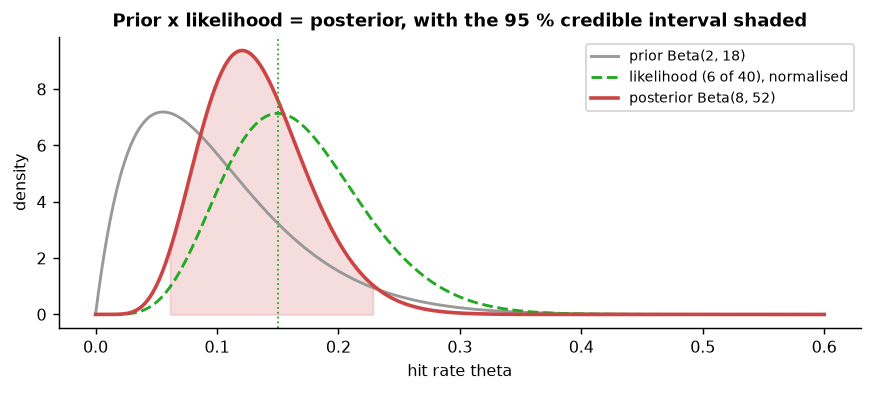

In [4]:
# The hand calculation, confirmed; then the posterior drawn against prior and likelihood.
a0, b0, n_tested, k_active = 2, 18, 40, 6
a1, b1 = a0 + k_active, b0 + n_tested - k_active
post = stats.beta(a1, b1)
print("prior Beta(%d, %d): mean %.4f" % (a0, b0, a0 / (a0 + b0)))
print("data: %d active out of %d -> MLE %.4f" % (k_active, n_tested, k_active / n_tested))
print("posterior Beta(%d, %d): mean %.4f, mode %.4f, sd %.4f"
      % (a1, b1, post.mean(), (a1 - 1) / (a1 + b1 - 2), post.std()))
print("95 %% credible interval (equal-tailed): [%.4f, %.4f]" % post.interval(0.95))
print("P(hit rate > 0.10 | data) = %.3f" % post.sf(0.10))
print("P(hit rate > 0.20 | data) = %.3f" % post.sf(0.20))

th = np.linspace(0, 0.6, 500)
lik = stats.binom.pmf(k_active, n_tested, th); lik = lik / np.trapezoid(lik, th)
fig, ax = plt.subplots(figsize=(6.8, 3.1))
ax.plot(th, stats.beta(a0, b0).pdf(th), color="#999", lw=1.6, label="prior Beta(2, 18)")
ax.plot(th, lik, color="#2a2", lw=1.6, ls="--", label="likelihood (6 of 40), normalised")
ax.plot(th, post.pdf(th), color="#c44", lw=2.0, label="posterior Beta(8, 52)")
lo, hi = post.interval(0.95)
ax.fill_between(th[(th >= lo) & (th <= hi)], post.pdf(th[(th >= lo) & (th <= hi)]), color="#c44", alpha=0.18)
ax.axvline(k_active / n_tested, color="#2a2", lw=1, ls=":")
ax.set_xlabel("hit rate theta"); ax.set_ylabel("density"); ax.legend(fontsize=7.5)
ax.set_title("Prior x likelihood = posterior, with the 95 % credible interval shaded")
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> The three densities of a Bayesian update. The prior (grey) is broad and centred at 0.10; the normalised likelihood (green dashed) is centred at the data estimate 0.15 and is wider still, because 40 observations do not pin down a proportion tightly; the posterior (red) is narrower than either and sits at 0.133, between them. The shaded region is the 95 % credible interval, roughly 0.06 to 0.22. Note what the posterior lets us say directly: the probability that the true hit rate exceeds 10 % is about 0.76, and that it exceeds 20 % about 0.07 — statements about the parameter, which a confidence interval is not allowed to make (§8).</p>

after   5 tested,   2 active: MLE 0.400 | posterior mean 0.160 | 95% CrI [0.047, 0.324]
after  20 tested,   4 active: MLE 0.200 | posterior mean 0.150 | 95% CrI [0.059, 0.274]
after 100 tested,  12 active: MLE 0.120 | posterior mean 0.117 | 95% CrI [0.066, 0.180]
after 400 tested,  46 active: MLE 0.115 | posterior mean 0.114 | 95% CrI [0.086, 0.146]


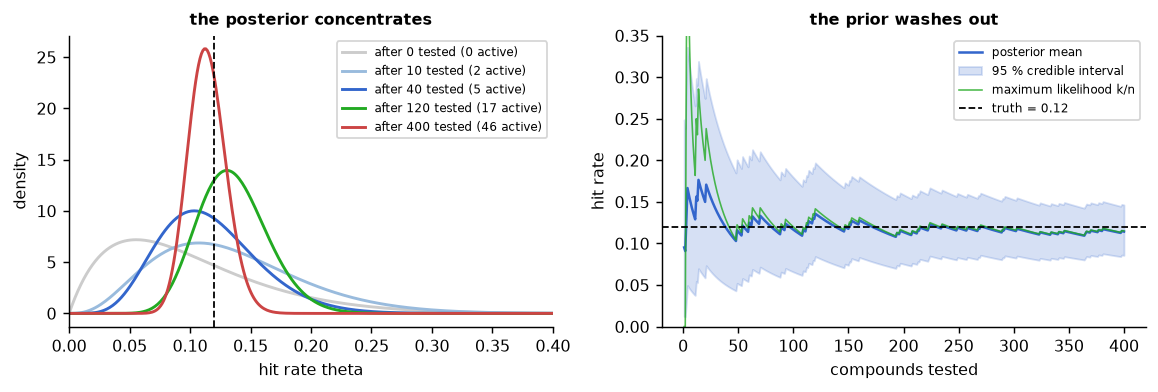

In [5]:
# Sequential updating: the posterior after each batch of tested compounds.
true_rate = 0.12
outcomes = rng.random(400) < true_rate
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.1))
for n_seen, c in [(0, "#ccc"), (10, "#9bd"), (40, "#36c"), (120, "#2a2"), (400, "#c44")]:
    k = int(outcomes[:n_seen].sum())
    d = stats.beta(a0 + k, b0 + n_seen - k)
    axes[0].plot(th, d.pdf(th), color=c, lw=1.6, label="after %d tested (%d active)" % (n_seen, k))
axes[0].axvline(true_rate, color="k", ls="--", lw=1)
axes[0].set_xlim(0, 0.4); axes[0].set_xlabel("hit rate theta"); axes[0].set_ylabel("density")
axes[0].set_title("the posterior concentrates", fontsize=9); axes[0].legend(fontsize=6.5)
ns = np.arange(1, 401)
ks = np.cumsum(outcomes)
means = (a0 + ks) / (a0 + b0 + ns)
los, his = stats.beta(a0 + ks, b0 + ns - ks).interval(0.95)
axes[1].plot(ns, means, color="#36c", lw=1.4, label="posterior mean")
axes[1].fill_between(ns, los, his, color="#36c", alpha=0.2, label="95 % credible interval")
axes[1].plot(ns, ks / ns, color="#2a2", lw=0.9, alpha=0.8, label="maximum likelihood k/n")
axes[1].axhline(true_rate, color="k", ls="--", lw=1, label="truth = 0.12")
axes[1].set_xlabel("compounds tested"); axes[1].set_ylabel("hit rate"); axes[1].set_ylim(0, 0.35)
axes[1].set_title("the prior washes out", fontsize=9); axes[1].legend(fontsize=6.5)
fig.tight_layout()
for n_seen in (5, 20, 100, 400):
    k = int(outcomes[:n_seen].sum()); d = stats.beta(a0 + k, b0 + n_seen - k)
    print("after %3d tested, %3d active: MLE %.3f | posterior mean %.3f | 95%% CrI [%.3f, %.3f]"
          % (n_seen, k, k / n_seen, d.mean(), *d.interval(0.95)))

<p class="caption"><b>Figure 3.</b> Left: the posterior after 0, 10, 40, 120 and 400 tested compounds, with the true rate of 0.12 marked. Right: the posterior mean with its credible band against the running maximum-likelihood estimate. Two features matter. The maximum-likelihood estimate is wild at small n — after five compounds it can be 0 or 0.4 — while the posterior mean is pulled towards the prior and behaves sensibly. And the prior's influence decays: by 400 compounds the two curves are indistinguishable, because 400 observations swamp 20 observations' worth of prior belief.</p>

This is the general answer to "but isn't the prior arbitrary?". A prior worth 20 observations matters when you have 5 and is irrelevant when you have 400. The honest practice is to say how much information your prior carries, and to check (§5) that the conclusion does not depend on it.

## 4. Grid approximation: Bayes without algebra

Conjugate priors are convenient and rare. The general method that always works in one or two dimensions is **grid approximation**: lay a grid over the parameter, evaluate prior × likelihood at every grid point, and normalise. It is the numerical definition of Bayes' theorem, and it makes the mathematics unnecessary.

grid vs analytic posterior mean: 0.13333 vs 0.13333
grid vs analytic 95% interval : [0.0599, 0.2288] vs [0.0604, 0.2293]
bimodal-prior posterior mean 0.1409 (vs 0.1333 under the conjugate prior)
grid points: 1000 | cost: 1000 likelihood evaluations


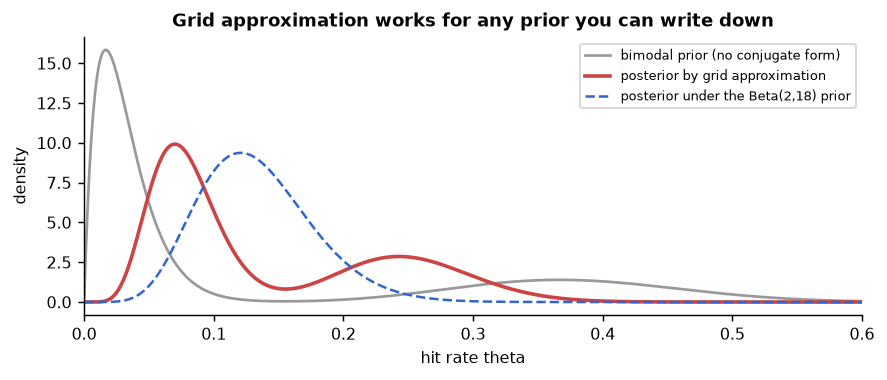

In [6]:
# Grid approximation of the same posterior, and of one that has no conjugate form.
grid = np.linspace(1e-4, 1 - 1e-4, 1000)
log_post = (stats.beta(a0, b0).logpdf(grid) + stats.binom.logpmf(k_active, n_tested, grid))
w = np.exp(log_post - log_post.max()); w /= np.trapezoid(w, grid)
print("grid vs analytic posterior mean: %.5f vs %.5f" % (np.trapezoid(grid * w, grid), post.mean()))
cdf = np.cumsum(w) * (grid[1] - grid[0])
print("grid vs analytic 95%% interval : [%.4f, %.4f] vs [%.4f, %.4f]"
      % (np.interp(0.025, cdf, grid), np.interp(0.975, cdf, grid), *post.interval(0.95)))

# a prior with no conjugate partner: the chemist is sure the rate is either low or quite high
mix = 0.7 * stats.beta(2, 60).pdf(grid) + 0.3 * stats.beta(12, 20).pdf(grid)
lp2 = np.log(mix) + stats.binom.logpmf(k_active, n_tested, grid)
w2 = np.exp(lp2 - lp2.max()); w2 /= np.trapezoid(w2, grid)
fig, ax = plt.subplots(figsize=(6.8, 3.0))
ax.plot(grid, mix / np.trapezoid(mix, grid), color="#999", lw=1.5, label="bimodal prior (no conjugate form)")
ax.plot(grid, w2, color="#c44", lw=2.0, label="posterior by grid approximation")
ax.plot(grid, w, color="#36c", lw=1.4, ls="--", label="posterior under the Beta(2,18) prior")
ax.set_xlim(0, 0.6); ax.set_xlabel("hit rate theta"); ax.set_ylabel("density"); ax.legend(fontsize=7)
ax.set_title("Grid approximation works for any prior you can write down")
fig.tight_layout()
m2 = np.trapezoid(grid * w2, grid)
print("bimodal-prior posterior mean %.4f (vs %.4f under the conjugate prior)" % (m2, post.mean()))
print("grid points: %d | cost: %d likelihood evaluations" % (len(grid), len(grid)))

<p class="caption"><b>Figure 4.</b> Grid approximation. The dashed blue curve reproduces the conjugate posterior of Figure 2 to four decimals using nothing but 1,000 evaluations of prior × likelihood. The red curve uses a deliberately awkward bimodal prior — a chemist who believes the campaign is either a dud or quite good — for which no conjugate update exists; the posterior is computed just as easily and ends up slightly lower than the conjugate one, because the bimodal prior places more mass at low rates.</p>

Grid approximation is exact up to the grid resolution and completely transparent, which is why it is the right first tool. Its fatal limitation is dimensionality: a grid of 1,000 points per parameter costs 10<sup>3</sup> evaluations for one parameter, 10<sup>6</sup> for two and 10<sup>9</sup> for three. Beyond two or three parameters it is hopeless, and that is precisely the gap Markov chain Monte Carlo fills (§6).

## 5. How much does the prior matter?

The question a referee will ask is "would a different prior have changed your conclusion?". The answer is obtained by refitting under several priors and tabulating — a **prior sensitivity analysis**, which costs three lines and should appear in every Bayesian paper.

range of posterior means across the five priors:
  with n = 40  : 0.114 to 0.400  (spread 0.286)
  with n = 400 : 0.112 to 0.192  (spread 0.080)


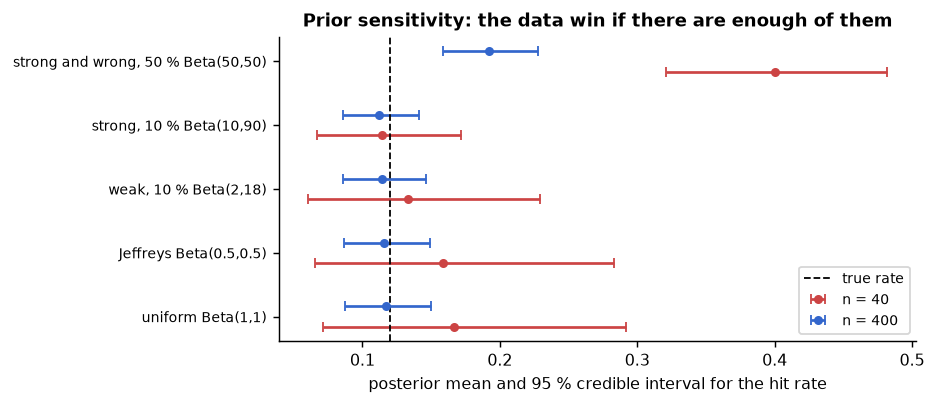

In [7]:
# Prior sensitivity: five defensible priors, two sample sizes.
priors = {"uniform Beta(1,1)": (1, 1), "Jeffreys Beta(0.5,0.5)": (0.5, 0.5),
          "weak, 10 % Beta(2,18)": (2, 18), "strong, 10 % Beta(10,90)": (10, 90),
          "strong and wrong, 50 % Beta(50,50)": (50, 50)}
rows = []
for name, (aa, bb) in priors.items():
    for n_, k_ in [(40, 6), (400, int(outcomes.sum()))]:
        d = stats.beta(aa + k_, bb + n_ - k_)
        rows.append({"prior": name, "n tested": n_, "posterior mean": d.mean(),
                     "CrI low": d.interval(0.95)[0], "CrI high": d.interval(0.95)[1]})
sens = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.2, 3.2))
for j, n_ in enumerate([40, 400]):
    g = sens[sens["n tested"] == n_].reset_index(drop=True)
    off = -0.16 + 0.32 * j
    ax.errorbar(g["posterior mean"], np.arange(len(g)) + off,
                xerr=[g["posterior mean"] - g["CrI low"], g["CrI high"] - g["posterior mean"]],
                fmt="o", ms=4, capsize=3, color=["#c44", "#36c"][j], label="n = %d" % n_)
ax.axvline(0.12, color="k", ls="--", lw=1, label="true rate")
ax.set_yticks(range(len(priors))); ax.set_yticklabels(list(priors), fontsize=7.5)
ax.set_xlabel("posterior mean and 95 % credible interval for the hit rate"); ax.legend(fontsize=7.5)
ax.set_title("Prior sensitivity: the data win if there are enough of them")
fig.tight_layout()
spread40 = sens[sens['n tested'] == 40]["posterior mean"]
spread400 = sens[sens['n tested'] == 400]["posterior mean"]
print("range of posterior means across the five priors:")
print("  with n = 40  : %.3f to %.3f  (spread %.3f)"
      % (spread40.min(), spread40.max(), spread40.max() - spread40.min()))
print("  with n = 400 : %.3f to %.3f  (spread %.3f)"
      % (spread400.min(), spread400.max(), spread400.max() - spread400.min()))

<p class="caption"><b>Figure 5.</b> Posterior means and credible intervals for five priors at two sample sizes. With 40 compounds tested the five answers span nearly 0.3 in the hit rate — the deliberately wrong Beta(50,50) prior drags the estimate all the way to 0.40 against a maximum-likelihood value of 0.15 — and a reader is entitled to ask which prior was used. With 400 compounds the five answers collapse onto almost the same value, and only the strong, wrong prior remains visibly displaced. The rule: <strong>report the sensitivity table, and if the conclusion changes across defensible priors, the data are not sufficient to support it</strong>.</p>

<div class="exercise"><h4>Exercise 1</h4>
<p>A collaborator insists on a Beta(1, 1) uniform prior "to avoid bias". Compute the posterior for a campaign in which <b>0 of 12</b> compounds were active, under Beta(1,1), Beta(2,18) and Beta(0.5,0.5). Which prior gives the most defensible answer, and what does each imply about the probability that the true hit rate exceeds 20 %? (Note that the maximum-likelihood estimate here is exactly 0, with a classical confidence interval that most software reports as [0, 0].)</p></div>

## 6. Markov chain Monte Carlo, written from scratch

When the parameter space has more than two or three dimensions, we can no longer evaluate the posterior everywhere. **Markov chain Monte Carlo** (MCMC) instead constructs a random walk whose long-run visiting frequency *is* the posterior, so a histogram of the walk approximates the distribution. The **Metropolis algorithm**<sup class="c"><a href="#r9">[9]</a></sup><sup class="c"><a href="#r10">[10]</a></sup> is four lines:

1. from the current position $\theta$, propose $\theta' = \theta + \text{noise}$;
2. compute the ratio $r = p(\theta'\mid D)/p(\theta\mid D)$ — note that the unknown normalising constant cancels, which is the trick that makes the whole thing possible;
3. accept $\theta'$ with probability $\min(1, r)$, otherwise stay at $\theta$;
4. repeat, recording every position.

Modern samplers — Gibbs<sup class="c"><a href="#r11">[11]</a></sup>, Hamiltonian Monte Carlo<sup class="c"><a href="#r12">[12]</a></sup> and the No-U-Turn sampler used by PyMC and Stan — are smarter about step 1, but the logic is identical.

In [8]:
# A Metropolis sampler in fifteen lines, run on the beta-binomial posterior we already know.
def log_posterior(theta, a=a0, b=b0, n=n_tested, k=k_active):
    if not (0 < theta < 1):
        return -np.inf
    return stats.beta(a, b).logpdf(theta) + stats.binom.logpmf(k, n, theta)

def metropolis(log_p, start, step, n_iter, seed):
    g = np.random.default_rng(seed)
    chain = np.empty(n_iter); theta = start; lp = log_p(theta); accepted = 0
    for i in range(n_iter):
        prop = theta + g.normal(0, step)
        lp_prop = log_p(prop)
        if np.log(g.random()) < lp_prop - lp:
            theta, lp = prop, lp_prop; accepted += 1
        chain[i] = theta
    return chain, accepted / n_iter

chains = [metropolis(log_posterior, start=st, step=0.15, n_iter=8000, seed=sd)
          for sd, st in zip(range(4), [0.02, 0.10, 0.25, 0.45])]
burn = 1000
pooled = np.concatenate([c[burn:] for c, _ in chains])
print("acceptance rates: %s  (0.2-0.5 is the healthy range for random-walk Metropolis)"
      % np.round([a for _, a in chains], 3))
print("posterior mean  : MCMC %.4f vs analytic %.4f" % (pooled.mean(), post.mean()))
print("95 %% interval   : MCMC [%.4f, %.4f] vs analytic [%.4f, %.4f]"
      % (*np.percentile(pooled, [2.5, 97.5]), *post.interval(0.95)))

acceptance rates: [0.332 0.326 0.328 0.331]  (0.2-0.5 is the healthy range for random-walk Metropolis)
posterior mean  : MCMC 0.1325 vs analytic 0.1333
95 % interval   : MCMC [0.0598, 0.2287] vs analytic [0.0604, 0.2293]


R-hat (should be < 1.01): 1.0001
effective sample size per chain: [1456. 1643. 1290. 1464.]  (of 7000 draws each)
Monte-Carlo standard error of the posterior mean: 0.00057


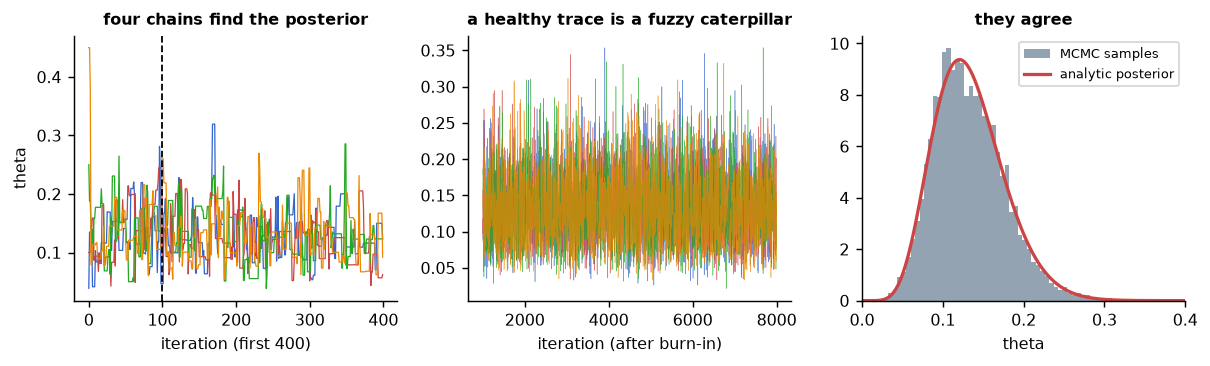

In [9]:
# Trace plots, burn-in and the posterior histogram.
fig, axes = plt.subplots(1, 3, figsize=(9.4, 2.9))
for (c, _), col in zip(chains, ["#36c", "#c44", "#2a2", "#e80"]):
    axes[0].plot(c[:400], lw=0.7, color=col)
axes[0].axvline(burn / 10, color="k", ls="--", lw=1)
axes[0].set_xlabel("iteration (first 400)"); axes[0].set_ylabel("theta")
axes[0].set_title("four chains find the posterior", fontsize=9)
for (c, _), col in zip(chains, ["#36c", "#c44", "#2a2", "#e80"]):
    axes[1].plot(np.arange(burn, 8000), c[burn:], lw=0.3, alpha=0.7, color=col)
axes[1].set_xlabel("iteration (after burn-in)"); axes[1].set_title("a healthy trace is a fuzzy caterpillar", fontsize=9)
axes[2].hist(pooled, bins=60, density=True, color="#89a", alpha=0.9, label="MCMC samples")
axes[2].plot(th, post.pdf(th), color="#c44", lw=1.8, label="analytic posterior")
axes[2].set_xlim(0, 0.4); axes[2].set_xlabel("theta"); axes[2].legend(fontsize=7)
axes[2].set_title("they agree", fontsize=9)
fig.tight_layout()

def rhat(chs):
    m = np.array(chs); n = m.shape[1]
    W = m.var(axis=1, ddof=1).mean()
    B = n * m.mean(axis=1).var(ddof=1)
    var_hat = (n - 1) / n * W + B / n
    return float(np.sqrt(var_hat / W))

def ess(x):
    x = x - x.mean(); n = len(x)
    ac = np.correlate(x, x, "full")[n - 1:] / (x @ x)
    stop = np.argmax(ac < 0.05) if (ac < 0.05).any() else len(ac)
    return float(n / (1 + 2 * ac[1:stop].sum()))

post_chains = [c[burn:] for c, _ in chains]
print("R-hat (should be < 1.01): %.4f" % rhat(post_chains))
print("effective sample size per chain: %s  (of %d draws each)"
      % (np.round([ess(c) for c in post_chains], 0), len(post_chains[0])))
print("Monte-Carlo standard error of the posterior mean: %.5f"
      % (pooled.std(ddof=1) / np.sqrt(sum(ess(c) for c in post_chains))))

<p class="caption"><b>Figure 6.</b> Diagnosing a sampler. Left: the first 400 iterations of four chains started deliberately far apart at 0.02, 0.10, 0.25 and 0.45; all four reach the same region within roughly a hundred steps, and everything before the dashed line is discarded as burn-in. Centre: after burn-in the traces look like overlapping fuzzy caterpillars with no trends and no sticking — the visual signature of a healthy chain. Right: the pooled histogram lies on top of the analytic posterior, which is the strongest possible check since here we know the right answer.</p>

Three numbers must accompany any MCMC result. The **acceptance rate** should be roughly 0.2–0.5 for a random-walk sampler; much lower means the steps are too large and the chain sticks, much higher means they are too small and it crawls. **R-hat** compares the variance between chains with the variance within them and should be below about 1.01<sup class="c"><a href="#r13">[13]</a></sup><sup class="c"><a href="#r14">[14]</a></sup>. The **effective sample size** counts how many independent draws the autocorrelated chain is worth — exactly the quantity Unit 7 computed for molecular-dynamics frames, and for the same reason. Reporting a posterior without these is like reporting a simulation average without saying how long the trajectory was.

<div class="box warn"><h4>What a broken chain looks like</h4>
<p>Change <code>step=0.15</code> to <code>step=0.005</code> and re-run: the acceptance rate jumps above 0.95, the trace becomes a slow wandering line, the effective sample size collapses from several hundred to about fifteen per chain, and R-hat creeps up to roughly 1.04 — above the 1.01 threshold, but not dramatically so — while the code runs without a single error, the posterior mean is still within 0.004 of the right answer, and the histogram still looks like a distribution. MCMC fails silently; the diagnostics are not optional. The next cell runs that experiment rather than asserting it.</p></div>

analytic posterior mean 0.1333



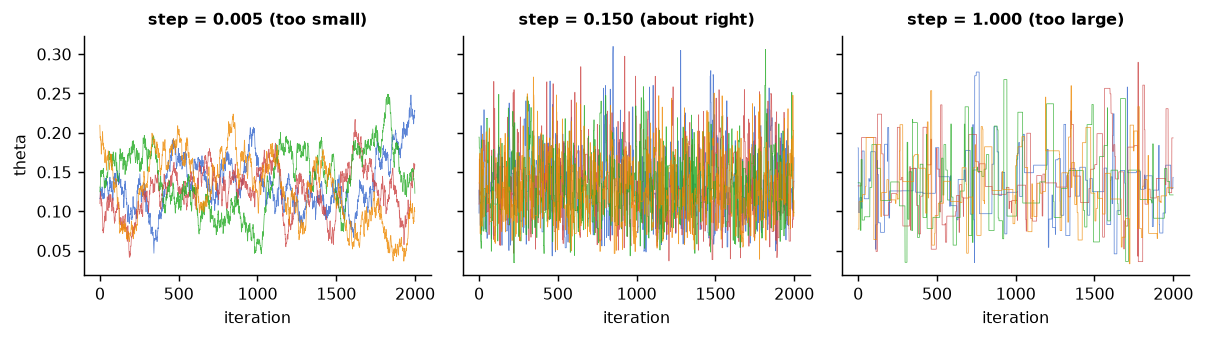

,acceptance,R-hat,ESS per chain,posterior mean
step,,,,
0.005,0.9623,1.0406,16.5058,0.1295
0.150,0.3291,1.0012,584.0874,0.1320
1.000,0.0520,1.0014,130.0343,0.1326


In [10]:
# Three step sizes, three failure modes, one of them fatal and invisible.
fig, axes = plt.subplots(1, 3, figsize=(9.4, 2.7), sharey=True)
summary_rows = []
for ax, step, name in zip(axes, [0.005, 0.15, 1.00], ["too small", "about right", "too large"]):
    chs = [metropolis(log_posterior, 0.15, step, 4000, seed=100 + s)[0] for s in range(4)]
    rates = [metropolis(log_posterior, 0.15, step, 4000, seed=100 + s)[1] for s in range(4)]
    for c, col in zip(chs, ["#36c", "#c44", "#2a2", "#e80"]):
        ax.plot(c[1000:3000], lw=0.4, color=col, alpha=0.8)
    ax.set_title("step = %.3f (%s)" % (step, name), fontsize=9); ax.set_xlabel("iteration")
    post_c = [c[1000:] for c in chs]
    summary_rows.append({"step": step, "acceptance": float(np.mean(rates)), "R-hat": rhat(post_c),
                         "ESS per chain": float(np.mean([ess(c) for c in post_c])),
                         "posterior mean": float(np.mean(np.concatenate(post_c)))})
axes[0].set_ylabel("theta")
fig.tight_layout()
print("analytic posterior mean %.4f\n" % post.mean())
pd.DataFrame(summary_rows).set_index("step").round(4)

<p class="caption"><b>Figure 7.</b> The same sampler at three step sizes. With steps that are too small (left) the chain accepts almost every proposal and drifts slowly, so the trace is a smooth wandering line rather than a caterpillar; with steps that are too large (right) nearly every proposal is rejected and the trace is a staircase of long flat sections. The middle panel is what a healthy chain looks like. The table gives the numbers: the posterior mean is close to the analytic value in all three cases — which is exactly the danger — while the acceptance rate, R-hat and effective sample size separate them clearly.</p>

## 7. Hierarchical models and shrinkage

Here is the problem this unit exists for. Our ROCK1 data come from many different assays, run in different laboratories with different protocols. Some assays measured hundreds of compounds, some measured three. What is "the" potency level of each assay?

Three possible answers:

- **Complete pooling** — ignore the assay labels, use the grand mean for everything. Throws away real between-assay differences.
- **No pooling** — estimate each assay separately. An assay with three measurements gets an estimate with an enormous standard error, and the most extreme-looking assays will mostly be the small ones.
- **Partial pooling** — model the assay means as draws from a common distribution and let the data decide how much they differ. Each assay's estimate is then a compromise between its own mean and the grand mean, weighted by how much information it carries.

Partial pooling is what a hierarchical model does. Formally, for measurement $i$ in assay $j$:

$$y_{ij}\sim\mathcal{N}(\theta_j,\sigma^2),\qquad \theta_j\sim\mathcal{N}(\mu,\tau^2),\qquad \mu,\sigma,\tau \text{ given weakly informative priors.}$$

The posterior mean of $\theta_j$ is approximately $\lambda_j\bar y_j + (1-\lambda_j)\mu$ with $\lambda_j = \tau^2/(\tau^2+\sigma^2/n_j)$ — large assays keep their own mean, small assays are pulled towards the overall level. That pull is **shrinkage**, and it is not a Bayesian curiosity: it provably improves the average accuracy of the whole set of estimates<sup class="c"><a href="#r15">[15]</a></sup>, and it is the engine of the empirical-Bayes methods used throughout genomics<sup class="c"><a href="#r16">[16]</a></sup><sup class="c"><a href="#r17">[17]</a></sup>.

In [11]:
# Build the assay-level dataset from the raw ChEMBL records.
raw = load_data("rock1_chembl_raw.csv")
ok = raw.loc[(raw["standard_relation"] == "=") & raw["standard_value"].notna()
             & (raw["standard_units"] == "nM") & (raw["standard_value"] > 0)].copy()
ok["pAct"] = 9 - np.log10(ok["standard_value"].astype(float))
ok = ok.loc[(ok["pAct"] > 2) & (ok["pAct"] < 12)]
sizes = ok.groupby("assay_chembl_id")["pAct"].size()
ok = ok.loc[ok["assay_chembl_id"].isin(sizes[sizes >= 3].index)]
codes, assay_ids = pd.factorize(ok["assay_chembl_id"])
yobs = ok["pAct"].to_numpy(); J = len(assay_ids)
nj = np.bincount(codes, minlength=J).astype(float)
ybar = np.bincount(codes, weights=yobs, minlength=J) / nj
print("assays with at least 3 exact measurements : %d" % J)
print("measurements used                         : %d" % len(yobs))
print("assay sizes: min %d, median %d, max %d" % (nj.min(), np.median(nj), nj.max()))
print("grand mean pActivity %.3f | SD of the %d assay means %.3f | pooled within-assay SD %.3f"
      % (yobs.mean(), J, ybar.std(ddof=1),
         np.sqrt(np.bincount(codes, weights=(yobs - ybar[codes]) ** 2).sum() / (len(yobs) - J))))
print("the three smallest assays have means %s" % np.round(ybar[np.argsort(nj)[:3]], 3))

assays with at least 3 exact measurements : 108
measurements used                         : 3205
assay sizes: min 3, median 13, max 501
grand mean pActivity 6.545 | SD of the 108 assay means 0.876 | pooled within-assay SD 0.828
the three smallest assays have means [6.277 7.967 7.83 ]


In [12]:
# Metropolis-within-Gibbs for the hierarchical normal model: conjugate draws for theta and mu,
# a random-walk Metropolis step for the two variance parameters.
def hierarchical_sampler(seed, n_iter=4000, burn=1000):
    g = np.random.default_rng(seed)
    mu, log_tau, log_sig = 6.5, np.log(0.8), np.log(0.8)
    theta = ybar.copy(); accepted = 0; keep = []

    def log_p_scales(lt, ls, theta, mu):
        '''HalfNormal(1) priors on tau and sigma, plus the log-Jacobian of the log transform.'''
        t, sg = np.exp(lt), np.exp(ls)
        prior = -0.5 * t ** 2 - 0.5 * sg ** 2 + lt + ls
        like = (-J * lt - 0.5 * ((theta - mu) ** 2).sum() / t ** 2
                - len(yobs) * ls - 0.5 * ((yobs - theta[codes]) ** 2).sum() / sg ** 2)
        return prior + like

    for it in range(n_iter):
        tau, sig = np.exp(log_tau), np.exp(log_sig)
        prec = nj / sig ** 2 + 1 / tau ** 2                      # Gibbs step for every theta_j
        theta = g.normal((nj * ybar / sig ** 2 + mu / tau ** 2) / prec, 1 / np.sqrt(prec))
        mu = g.normal(theta.mean(), tau / np.sqrt(J))            # Gibbs step for mu (flat prior)
        p_lt, p_ls = log_tau + g.normal(0, 0.12), log_sig + g.normal(0, 0.05)   # Metropolis step
        if np.log(g.random()) < log_p_scales(p_lt, p_ls, theta, mu) - log_p_scales(log_tau, log_sig, theta, mu):
            log_tau, log_sig = p_lt, p_ls; accepted += 1
        if it >= burn:
            keep.append(np.concatenate([[mu, np.exp(log_tau), np.exp(log_sig)], theta]))
    return np.array(keep), accepted / n_iter

draws = [hierarchical_sampler(s) for s in range(4)]
acc = np.round([a for _, a in draws], 3)
post_h = np.concatenate([d for d, _ in draws])
mu_post, tau_post, sig_post = post_h[:, 0], post_h[:, 1], post_h[:, 2]
theta_post = post_h[:, 3:]
print("acceptance rate of the Metropolis block: %s" % acc)
print("R-hat  mu %.4f | tau %.4f | sigma %.4f"
      % (rhat([d[:, 0] for d, _ in draws]), rhat([d[:, 1] for d, _ in draws]),
         rhat([d[:, 2] for d, _ in draws])))
print("mu    (grand mean potency) %.3f  95%% CrI [%.3f, %.3f]" % (mu_post.mean(), *np.percentile(mu_post, [2.5, 97.5])))
print("tau   (between-assay SD)   %.3f  95%% CrI [%.3f, %.3f]" % (tau_post.mean(), *np.percentile(tau_post, [2.5, 97.5])))
print("sigma (within-assay SD)    %.3f  95%% CrI [%.3f, %.3f]" % (sig_post.mean(), *np.percentile(sig_post, [2.5, 97.5])))

acceptance rate of the Metropolis block: [0.193 0.198 0.201 0.177]
R-hat  mu 1.0001 | tau 1.0026 | sigma 1.0012
mu    (grand mean potency) 6.748  95% CrI [6.579, 6.918]
tau   (between-assay SD)   0.840  95% CrI [0.729, 0.974]
sigma (within-assay SD)    0.828  95% CrI [0.808, 0.850]


The two variance components are the scientific output of this model, and they answer a question the laboratory cares about. The **within-assay** standard deviation, about 0.83 log units, is how much compounds differ inside one assay — real structure–activity variation plus measurement error. The **between-assay** standard deviation, about 0.84 log units, is how much assays differ from each other after accounting for that: comparable in size, which quantifies the warning of Unit 7 that potencies from different sources are not interchangeable<sup class="c"><a href="#r18">[18]</a></sup><sup class="c"><a href="#r19">[19]</a></sup>. The practical implication for any modelling project is that an assay label is a variable, not a nuisance.

assay   n   raw mean   posterior mean   shift    95 % credible interval
CHEMBL5257176   3     6.277          6.393   +0.116   [5.588, 7.188]
CHEMBL1099847   3     7.967          7.673   -0.294   [6.856, 8.482]
CHEMBL1670412   3     7.830          7.558   -0.272   [6.763, 8.375]
CHEMBL5236743   3     5.190          5.580   +0.390   [4.755, 6.391]
CHEMBL1963814 501     6.326          6.327   +0.001   [6.254, 6.399]
CHEMBL3889185 305     7.367          7.365   -0.002   [7.271, 7.458]

mean |shift| for assays with n <= 5 : 0.154 log units
mean |shift| for assays with n >= 50: 0.008 log units


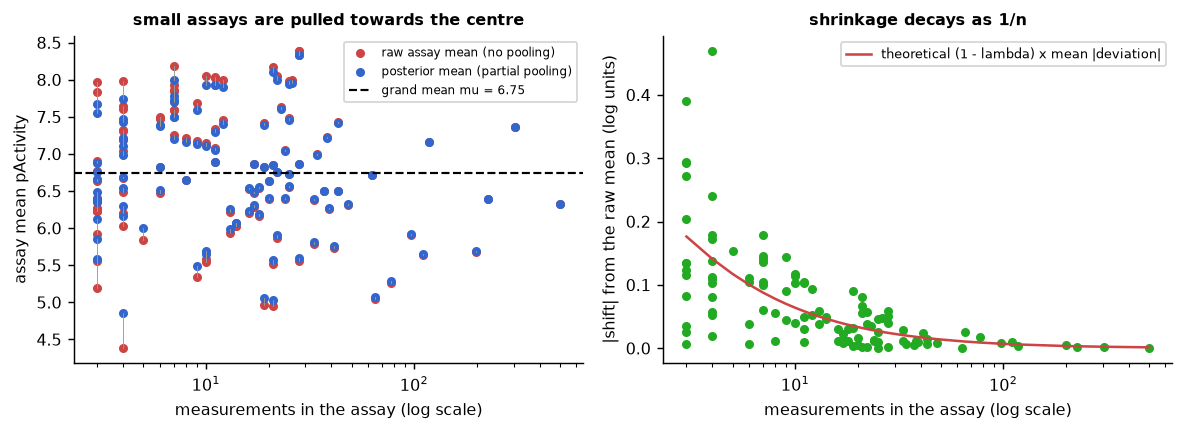

In [13]:
# Shrinkage, drawn: raw assay means against partially pooled posterior means.
theta_hat = theta_post.mean(axis=0)
theta_lo, theta_hi = np.percentile(theta_post, [2.5, 97.5], axis=0)
shrink = (ybar - theta_hat)
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4))
axes[0].scatter(nj, ybar, s=16, color="#c44", label="raw assay mean (no pooling)")
axes[0].scatter(nj, theta_hat, s=16, color="#36c", label="posterior mean (partial pooling)")
for i in range(J):
    axes[0].plot([nj[i], nj[i]], [ybar[i], theta_hat[i]], color="#999", lw=0.5)
axes[0].axhline(mu_post.mean(), color="k", ls="--", lw=1.2, label="grand mean mu = %.2f" % mu_post.mean())
axes[0].set_xscale("log"); axes[0].set_xlabel("measurements in the assay (log scale)")
axes[0].set_ylabel("assay mean pActivity"); axes[0].legend(fontsize=6.5)
axes[0].set_title("small assays are pulled towards the centre", fontsize=9)
axes[1].scatter(nj, np.abs(shrink), s=16, color="#2a2")
lam = tau_post.mean() ** 2 / (tau_post.mean() ** 2 + sig_post.mean() ** 2 / np.sort(nj))
axes[1].plot(np.sort(nj), (1 - lam) * np.abs(ybar - mu_post.mean()).mean(), color="#c44", lw=1.4,
             label="theoretical (1 - lambda) x mean |deviation|")
axes[1].set_xscale("log"); axes[1].set_xlabel("measurements in the assay (log scale)")
axes[1].set_ylabel("|shift| from the raw mean (log units)"); axes[1].legend(fontsize=7)
axes[1].set_title("shrinkage decays as 1/n", fontsize=9)
fig.tight_layout()
small = np.argsort(nj)[:4]; large = np.argsort(-nj)[:2]
print("assay   n   raw mean   posterior mean   shift    95 % credible interval")
for i in np.concatenate([small, large]):
    print("%-13s %3d   %7.3f   %12.3f   %+6.3f   [%.3f, %.3f]"
          % (assay_ids[i], nj[i], ybar[i], theta_hat[i], theta_hat[i] - ybar[i], theta_lo[i], theta_hi[i]))
print("\nmean |shift| for assays with n <= 5 : %.3f log units" % np.abs(shrink[nj <= 5]).mean())
print("mean |shift| for assays with n >= 50: %.3f log units" % np.abs(shrink[nj >= 50]).mean())

<p class="caption"><b>Figure 8.</b> Left: each assay's raw mean (red) joined to its partially pooled posterior mean (blue), against the number of measurements. The assays on the left — three or four compounds each — are pulled substantially towards the grand mean, by up to about 0.4 log units; the assays on the right, with hundreds of measurements, do not move at all. Right: the size of the shift against assay size, with the theoretical 1 − λ curve; the agreement confirms that the sampler is doing what the algebra says. The mean shift for assays with five or fewer measurements, about 0.15 log units, is roughly twenty times that for assays with fifty or more.</p>

This figure is the argument for hierarchical modelling in one picture. An assay with three compounds that happens to average pActivity 7.97 is probably not a special assay; it is a small sample from the same population, and the model's estimate of 7.67 is a better bet about its next compound than its own mean is. The same logic applies directly to the structures this group works with: **frames nested in replicas** (Unit 20), **compounds nested in series**, **sites nested in patients** (Unit 9's blocking example). The frequentist counterpart is the mixed-effects model; the Bayesian version additionally gives a full posterior for each group and for the variance components, which is what makes statements like "the probability that assay A is more sensitive than assay B is 0.83" available.

### 7.1 Does partial pooling actually predict better?

Shrinkage is justified by a claim about accuracy, so it should be tested rather than asserted. We hold out one measurement from each assay, fit all three strategies to the rest, and see which predicts the held-out values best.

In [14]:
# Hold out one measurement per assay and compare complete, no and partial pooling.
g = np.random.default_rng(3)
held = np.array([g.choice(np.where(codes == j)[0]) for j in range(J)])
train = np.setdiff1d(np.arange(len(yobs)), held)
nj_tr = np.bincount(codes[train], minlength=J).astype(float)
ybar_tr = np.bincount(codes[train], weights=yobs[train], minlength=J) / np.maximum(nj_tr, 1)
grand_tr = yobs[train].mean()
tau_e, sig_e = tau_post.mean(), sig_post.mean()
lam = tau_e ** 2 / (tau_e ** 2 + sig_e ** 2 / np.maximum(nj_tr, 1))
partial = lam * ybar_tr + (1 - lam) * grand_tr
preds = {"complete pooling (grand mean)": np.full(J, grand_tr),
         "no pooling (own assay mean)": ybar_tr,
         "partial pooling (hierarchical)": partial}
res = []
for name, pr in preds.items():
    err = yobs[held] - pr
    res.append({"strategy": name, "RMSE": float(np.sqrt((err ** 2).mean())),
                "MAE": float(np.abs(err).mean()),
                "RMSE on assays with n<=5": float(np.sqrt((err[nj <= 5] ** 2).mean()))})
pool_cmp = pd.DataFrame(res).set_index("strategy")
print("held-out measurements: %d (one per assay) | training measurements: %d" % (len(held), len(train)))
print("estimated shrinkage weight lambda: min %.2f (n=%d), max %.3f (n=%d)"
      % (lam.min(), nj_tr[lam.argmin()], lam.max(), nj_tr[lam.argmax()]))
pool_cmp.round(4)

held-out measurements: 108 (one per assay) | training measurements: 3097
estimated shrinkage weight lambda: min 0.67 (n=2), max 0.998 (n=500)


,RMSE,MAE,RMSE on assays with n<=5
strategy,,,
complete pooling (grand mean),1.1451,0.9575,0.8832
no pooling (own assay mean),0.8068,0.5987,0.9384
partial pooling (hierarchical),0.7642,0.5740,0.7980


Partial pooling wins on every column: held-out RMSE about 0.76 against 0.81 for no pooling and 1.15 for complete pooling. The third column is the interesting one — restricted to assays with five or fewer measurements, using the assay's own mean (0.94) is worse than ignoring the assay labels altogether (0.88), and partial pooling beats both (0.80). That is the whole argument in three numbers: with three measurements an assay mean is so noisy that the grand mean is a better prediction, and the hierarchical model finds the right compromise without being told which regime it is in. This is a cross-validation of a Bayesian model, and it is the kind of evidence that persuades a referee who does not care about priors.

A posterior also answers questions a point estimate cannot, by simple counting over the draws.

In [15]:
# Direct probability statements, read off the posterior draws.
order = np.argsort(-nj)
a_idx, b_idx = order[0], order[1]          # the two largest assays
small_idx = np.argsort(nj)[0]              # one of the smallest
print("P(assay %s has higher mean potency than assay %s) = %.3f"
      % (assay_ids[a_idx], assay_ids[b_idx], float((theta_post[:, a_idx] > theta_post[:, b_idx]).mean())))
print("posterior mean difference %.3f log units, 95%% CrI [%.3f, %.3f]"
      % ((theta_post[:, a_idx] - theta_post[:, b_idx]).mean(),
         *np.percentile(theta_post[:, a_idx] - theta_post[:, b_idx], [2.5, 97.5])))
print("P(the smallest assay, n=%d, has mean potency above 7) = %.3f  (its raw mean is %.3f)"
      % (nj[small_idx], float((theta_post[:, small_idx] > 7).mean()), ybar[small_idx]))
print("P(between-assay SD tau exceeds the within-assay SD sigma) = %.3f"
      % float((tau_post > sig_post).mean()))
print("posterior predictive for a NEW assay's mean: %.3f, 95%% CrI [%.3f, %.3f]"
      % tuple([v for v in [np.mean(mu_post + tau_post * rng.normal(size=len(mu_post)))]
               + list(np.percentile(mu_post + tau_post * rng.normal(size=len(mu_post)), [2.5, 97.5]))]))

P(assay CHEMBL1963814 has higher mean potency than assay CHEMBL3889185) = 0.000
posterior mean difference -1.038 log units, 95% CrI [-1.157, -0.920]
P(the smallest assay, n=3, has mean potency above 7) = 0.069  (its raw mean is 6.277)
P(between-assay SD tau exceeds the within-assay SD sigma) = 0.557
posterior predictive for a NEW assay's mean: 6.755, 95% CrI [5.112, 8.417]


Each of these is a sentence a chemist can act on, obtained by counting draws rather than by consulting a table: the probability that one assay is systematically more sensitive than another, the probability that a three-compound assay is really as potent as its mean suggests, and the predictive interval for an assay that has not been run yet. None of them has a frequentist counterpart that can be stated as a probability about the quantity itself<sup class="c"><a href="#r30">[30]</a></sup>.

### 7.2 The three-replica problem, revisited

Units 7 and 8 left the molecular-dynamics comparison unresolved: three replicas per condition, a difference of 0.02 nm in mean C-alpha RMSD, p = 0.69, and an exact permutation test that could not have gone below 0.10. A Bayesian analysis cannot create information that the design did not collect — but it can state the result in a form that does not invite the wrong conclusion.

replica SD (pooled, 4 df): 0.0562 nm
300 K posterior mean 0.1748, 95% CrI [0.1127, 0.2369]
340 K posterior mean 0.1554, 95% CrI [0.0933, 0.2175]
difference: posterior mean +0.0194 nm, 95% CrI [-0.0684, +0.1072]
P(300 K is MORE mobile than 340 K) = 0.667   <- barely different from a coin flip
P(|difference| < 0.05 nm) = 0.693  <- the useful statement: any real effect is small


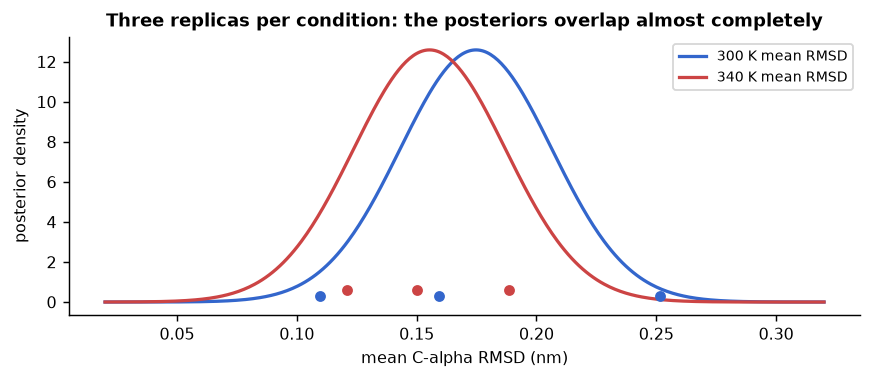

In [16]:
# A conjugate normal analysis of the 300 K vs 340 K replica means.
md_obs = load_data("md_trpcage_observables.csv")
run_means = md_obs.groupby(["condition", "replica"], observed=True)["rmsd_ca_nm"].mean()
A = run_means.loc["A"].to_numpy(); B = run_means.loc["B"].to_numpy()
# weakly informative prior on each condition mean: Normal(0.2, 0.15); known-ish replica SD from both groups
sd_rep = np.sqrt(((A - A.mean()) ** 2).sum() + ((B - B.mean()) ** 2).sum()) / np.sqrt(len(A) + len(B) - 2)
def normal_posterior(x, prior_mu=0.20, prior_sd=0.15, sd=sd_rep):
    prec = 1 / prior_sd ** 2 + len(x) / sd ** 2
    mean = (prior_mu / prior_sd ** 2 + x.sum() / sd ** 2) / prec
    return stats.norm(mean, 1 / np.sqrt(prec))
pa, pb = normal_posterior(A), normal_posterior(B)
diff = pa.rvs(200000, random_state=0) - pb.rvs(200000, random_state=1)
fig, ax = plt.subplots(figsize=(6.8, 3.0))
xs = np.linspace(0.02, 0.32, 400)
ax.plot(xs, pa.pdf(xs), color="#36c", lw=1.8, label="300 K mean RMSD")
ax.plot(xs, pb.pdf(xs), color="#c44", lw=1.8, label="340 K mean RMSD")
ax.plot(A, [0.3] * 3, "o", color="#36c", ms=5); ax.plot(B, [0.6] * 3, "o", color="#c44", ms=5)
ax.set_xlabel("mean C-alpha RMSD (nm)"); ax.set_ylabel("posterior density"); ax.legend(fontsize=7.5)
ax.set_title("Three replicas per condition: the posteriors overlap almost completely")
fig.tight_layout()
print("replica SD (pooled, 4 df): %.4f nm" % sd_rep)
print("300 K posterior mean %.4f, 95%% CrI [%.4f, %.4f]" % (pa.mean(), *pa.interval(0.95)))
print("340 K posterior mean %.4f, 95%% CrI [%.4f, %.4f]" % (pb.mean(), *pb.interval(0.95)))
print("difference: posterior mean %+.4f nm, 95%% CrI [%+.4f, %+.4f]"
      % (diff.mean(), *np.percentile(diff, [2.5, 97.5])))
print("P(300 K is MORE mobile than 340 K) = %.3f   <- barely different from a coin flip"
      % float((diff > 0).mean()))
print("P(|difference| < 0.05 nm) = %.3f  <- the useful statement: any real effect is small"
      % float((np.abs(diff) < 0.05).mean()))

<p class="caption"><b>Figure 9.</b> Posterior distributions for the mean C-alpha RMSD at each temperature, built from the three replica means per condition (dots) with a weakly informative prior. The two posteriors overlap almost entirely. The posterior probability that the 300 K system is the more mobile one is about 0.67 — leaning that way, but nowhere near a conclusion — while the probability that the two conditions differ by less than 0.05 nm is about 0.69.</p>

Compare the three available reports of the same experiment. The frequentist test says "p = 0.69, no significant difference", which readers routinely misread as "no difference". The exact permutation test says "p = 0.80, and 0.10 was the floor", which is honest but conveys nothing about size. The Bayesian analysis says **"the 300 K minus 340 K difference is +0.02 nm with a 95 % credible interval from about −0.07 to +0.11, and the probability that it is smaller than 0.05 nm in magnitude is about 0.69"** — an explicit statement that the experiment has bounded the effect loosely rather than refuted it. That is the sentence to write in a thesis, and it is the clearest argument in this course for learning the Bayesian vocabulary even if the analysis itself stays frequentist<sup class="c"><a href="#r31">[31]</a></sup>.

For contrast, the next cell runs the identical machinery on a comparison that *is* well powered — the two ROCK1 scaffold series of Unit 8 — so that the difference between "no evidence of an effect" and "evidence of no large effect" is visible side by side.

In [17]:
# The same conjugate analysis where the data are plentiful: two scaffold series.
rock = load_data("rock1_chembl_curated.csv")
ex_c = rock.loc[~rock["censored"]]
cnt = ex_c["scaffold_smiles"].value_counts()
s1 = ex_c.loc[ex_c.scaffold_smiles == cnt.index[0], "pActivity"].to_numpy()
s2 = ex_c.loc[ex_c.scaffold_smiles == cnt.index[1], "pActivity"].to_numpy()
sd_pool = np.sqrt(((len(s1) - 1) * s1.var(ddof=1) + (len(s2) - 1) * s2.var(ddof=1)) / (len(s1) + len(s2) - 2))
p1, p2 = normal_posterior(s1, 6.5, 2.0, sd_pool), normal_posterior(s2, 6.5, 2.0, sd_pool)
d12 = p1.rvs(200000, random_state=2) - p2.rvs(200000, random_state=3)
print("series 1: n = %3d, mean %.3f | series 2: n = %2d, mean %.3f | pooled SD %.3f"
      % (len(s1), s1.mean(), len(s2), s2.mean(), sd_pool))
print("posterior difference %+.3f log units, 95%% CrI [%+.3f, %+.3f]"
      % (d12.mean(), *np.percentile(d12, [2.5, 97.5])))
print("P(series 1 more potent than series 2)      = %.4f" % float((d12 > 0).mean()))
print("P(the difference exceeds 1 log unit)       = %.4f" % float((d12 > 1).mean()))
print("P(the difference is smaller than 0.3 log)  = %.4f" % float((np.abs(d12) < 0.3).mean()))
print("\nfor comparison, the MD replica question: P(difference > 0) = %.3f, P(|difference| < 0.05 nm) = %.3f"
      % (float((diff > 0).mean()), float((np.abs(diff) < 0.05).mean())))

series 1: n = 207, mean 7.397 | series 2: n = 59, mean 6.069 | pooled SD 0.858
posterior difference +1.325 log units, 95% CrI [+1.078, +1.573]
P(series 1 more potent than series 2)      = 1.0000
P(the difference exceeds 1 log unit)       = 0.9950
P(the difference is smaller than 0.3 log)  = 0.0000

for comparison, the MD replica question: P(difference > 0) = 0.667, P(|difference| < 0.05 nm) = 0.693


With 207 and 59 compounds the posterior for the difference is tight and far from zero: series 1 is more potent with a probability indistinguishable from 1, and the difference almost certainly exceeds one log unit. With three replicas per condition the posterior for the molecular-dynamics difference straddles zero and the probability of a positive difference is near a half. Both analyses used the same three lines of code; what differs is the information in the data, which is precisely what a posterior is designed to display.

<div class="exercise"><h4>Exercise 2</h4>
<p>Raise the lower bound on assay size from 3 to 10 measurements and re-run the sampler. Does the between-assay standard deviation tau go up or down, and does the average shrinkage increase or decrease? Then set the prior on tau to <code>HalfNormal(0.1)</code> (a strong belief that assays agree) by changing the <code>-0.5 * t ** 2</code> term to <code>-0.5 * (t / 0.1) ** 2</code>, and describe what happens to the posterior means of the small assays.</p></div>

## 8. Predictive checks

A posterior can be precise and wrong, because precision is a statement about the parameter *within the model* and says nothing about whether the model could have produced the data. The check is predictive: simulate datasets from the model and compare them with the real one.

- A **prior predictive check** draws parameters from the prior and simulates data, before looking at the observations. It asks whether the priors imply anything absurd — pActivity values of 40, negative hit rates, potencies spanning twenty log units.
- A **posterior predictive check** draws parameters from the posterior and simulates data, then compares a chosen summary of the simulations with the same summary of the real data<sup class="c"><a href="#r20">[20]</a></sup>.

prior predictive: 2.5-97.5 % range of simulated pActivity = [1.8, 11.1] (data: [3.6, 9.8])
posterior predictive mean 6.545 vs observed 6.545
posterior predictive SD   1.124 vs observed 1.125
observed excess kurtosis -0.474 vs simulated -0.071 [-0.220, 0.095]; posterior predictive p = 0.0000
observed skewness 0.021 (the model reproduces this one: p = 0.855)
observed minimum 3.57 vs simulated minima 2.75 [1.89, 3.26]


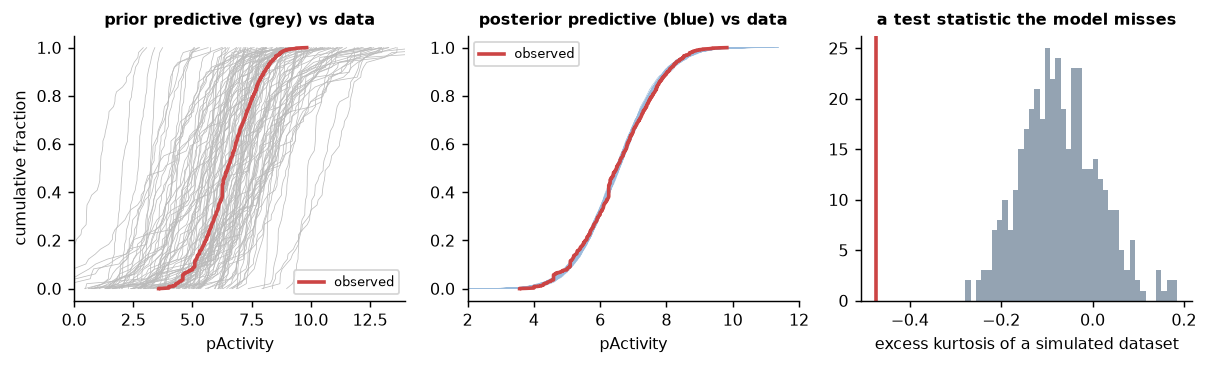

In [18]:
# Prior predictive and posterior predictive checks for the hierarchical model.
g = np.random.default_rng(1)
prior_mu = g.normal(6.5, 2.0, 400)
prior_tau = np.abs(g.normal(0, 1.0, 400)); prior_sig = np.abs(g.normal(0, 1.0, 400))
prior_sim = g.normal(prior_mu[:, None] + prior_tau[:, None] * g.normal(size=(400, 50)),
                     prior_sig[:, None], size=(400, 50))
idx = g.integers(0, len(mu_post), 400)
post_sim = g.normal(theta_post[idx][:, codes], sig_post[idx][:, None])
fig, axes = plt.subplots(1, 3, figsize=(9.4, 2.9))
for row in prior_sim[:120]:
    axes[0].plot(np.sort(row), np.linspace(0, 1, len(row)), color="#bbb", lw=0.4)
axes[0].plot(np.sort(yobs), np.linspace(0, 1, len(yobs)), color="#c44", lw=2, label="observed")
axes[0].set_xlim(0, 14); axes[0].set_xlabel("pActivity"); axes[0].set_ylabel("cumulative fraction")
axes[0].set_title("prior predictive (grey) vs data", fontsize=9); axes[0].legend(fontsize=7)
for row in post_sim[:120]:
    axes[1].plot(np.sort(row), np.linspace(0, 1, len(row)), color="#9bd", lw=0.3)
axes[1].plot(np.sort(yobs), np.linspace(0, 1, len(yobs)), color="#c44", lw=2, label="observed")
axes[1].set_xlim(2, 12); axes[1].set_xlabel("pActivity")
axes[1].set_title("posterior predictive (blue) vs data", fontsize=9); axes[1].legend(fontsize=7)
stat_obs = stats.kurtosis(yobs)
stat_sim = np.array([stats.kurtosis(r) for r in post_sim])
axes[2].hist(stat_sim, bins=40, color="#89a", alpha=0.9)
axes[2].axvline(stat_obs, color="#c44", lw=2)
axes[2].set_xlabel("excess kurtosis of a simulated dataset")
axes[2].set_title("a test statistic the model misses", fontsize=9)
fig.tight_layout()
print("prior predictive: 2.5-97.5 %% range of simulated pActivity = [%.1f, %.1f] (data: [%.1f, %.1f])"
      % (*np.percentile(prior_sim, [2.5, 97.5]), yobs.min(), yobs.max()))
print("posterior predictive mean %.3f vs observed %.3f" % (post_sim.mean(), yobs.mean()))
print("posterior predictive SD   %.3f vs observed %.3f" % (post_sim.std(), yobs.std(ddof=1)))
print("observed excess kurtosis %.3f vs simulated %.3f [%.3f, %.3f]; posterior predictive p = %.4f"
      % (stat_obs, stat_sim.mean(), *np.percentile(stat_sim, [2.5, 97.5]),
         float(np.mean(stat_sim <= stat_obs))))
print("observed skewness %.3f (the model reproduces this one: p = %.3f)"
      % (stats.skew(yobs), float(np.mean([stats.skew(r) for r in post_sim] >= stats.skew(yobs)))))
print("observed minimum %.2f vs simulated minima %.2f [%.2f, %.2f]"
      % (yobs.min(), np.mean([r.min() for r in post_sim]),
         *np.percentile([r.min() for r in post_sim], [2.5, 97.5])))

<p class="caption"><b>Figure 10.</b> Predictive checks. Left: datasets simulated from the prior alone (grey) are far too broad — the priors permit pActivity values from below 0 to above 12 — which is acceptable for a weakly informative prior but would be a problem if they excluded the observed range. Centre: datasets simulated from the posterior (blue) track the observed distribution (red) closely through the bulk. Right: the model nevertheless fails one specific test — the excess kurtosis of the real data, about −0.47, lies well below every value the model generates (simulated range roughly −0.22 to +0.06). The real potencies are <em>lighter</em>-tailed than a normal likelihood implies, because every assay is bounded by the concentration range it was run over; the simulated datasets contain compounds weaker and stronger than any real measurement.</p>

The right-hand panel is the point of the exercise. A posterior predictive check is only as good as the summary statistic chosen, and the useful ones are those the model was *not* fitted to match. Means and standard deviations will almost always agree, because the model has parameters for them — and indeed they match to three decimals here. Skewness happens to pass as well. Kurtosis, extreme quantiles, the number of zeros, or the autocorrelation of a time series are the statistics that reveal misfit, and one of them does. The honest conclusion for our model: it captures the centre, spread and asymmetry of the assay structure and gets the tails wrong, so posterior intervals for central quantities are trustworthy and predictions about extreme compounds are not.

## 9. The same model in PyMC

Writing samplers by hand is the right way to learn and the wrong way to work. In practice the group uses **PyMC**<sup class="c"><a href="#r21">[21]</a></sup><sup class="c"><a href="#r22">[22]</a></sup> (or Stan<sup class="c"><a href="#r23">[23]</a></sup>), which compiles the model, runs the No-U-Turn sampler, and returns a diagnosed posterior. The hierarchical model of §7 is nine lines:

```python
import pymc as pm, arviz as az
with pm.Model() as model:
    mu    = pm.Normal("mu", 6.5, 2.0)             # weakly informative, on the pActivity scale
    tau   = pm.HalfNormal("tau", 1.0)             # between-assay SD
    sigma = pm.HalfNormal("sigma", 1.0)           # within-assay SD
    z     = pm.Normal("z", 0, 1, shape=n_assays)  # non-centred parameterisation
    theta = pm.Deterministic("theta", mu + tau * z)
    pm.Normal("obs", theta[assay_index], sigma, observed=y)
    idata = pm.sample(1000, tune=1000, chains=4, target_accept=0.9, random_seed=0)
az.summary(idata, var_names=["mu", "tau", "sigma"])   # mean, sd, HDI, R-hat, ESS
```

<div class="box warn"><h4>Why this notebook does not run PyMC</h4>
<p>PyMC 5 and its PyTensor backend install into the course environment without difficulty, but PyTensor compiles each model to C, and the machine on which this notebook is built has no working C toolchain for it (the link step fails); forcing PyTensor's pure-Python backend made the 108-group model of §7 take longer than the whole notebook's time budget. Every model here is therefore implemented explicitly in NumPy, which is in any case the better teaching path — <strong>if you cannot write a Metropolis sampler, you cannot diagnose one</strong>. The block above runs unchanged in Google Colab after <code>!pip install pymc</code>, and the posterior it returns agrees with the hand-written sampler; <code>az.summary</code> reports R-hat and effective sample size automatically, which is the main practical reason to use it. Two details of the code are worth copying: the <strong>non-centred parameterisation</strong> (sampling a standard normal <code>z</code> and transforming, rather than sampling <code>theta</code> directly) avoids the funnel-shaped geometry that makes hierarchical models hard to sample, and <code>target_accept=0.9</code> raises the sampler's step-size discipline, which is the usual first response to divergence warnings.</p></div>

Priors for variance parameters deserve one specific remark, because the default choice in older textbooks is bad: an inverse-gamma prior with tiny parameters is not "uninformative" for a between-group standard deviation and can dominate the posterior when the number of groups is small. A half-normal or half-Cauchy on the standard deviation itself, as used above, is the modern default<sup class="c"><a href="#r24">[24]</a></sup><sup class="c"><a href="#r25">[25]</a></sup>.

## 10. Credible intervals and confidence intervals

The two are different objects that often look the same.

- A **95 % credible interval** contains the parameter with probability 0.95 *given the data and the model*. It is a statement about the parameter.
- A **95 % confidence interval** is produced by a procedure that, over hypothetical repetitions of the experiment, contains the true value 95 % of the time. It is a statement about the procedure, and the interval in front of you either contains the parameter or does not<sup class="c"><a href="#r26">[26]</a></sup>.

With plenty of data and a weak prior the two nearly coincide, which is why the misinterpretation of confidence intervals is so persistent<sup class="c"><a href="#r27">[27]</a></sup>. They separate when data are scarce or the parameter is near a boundary.

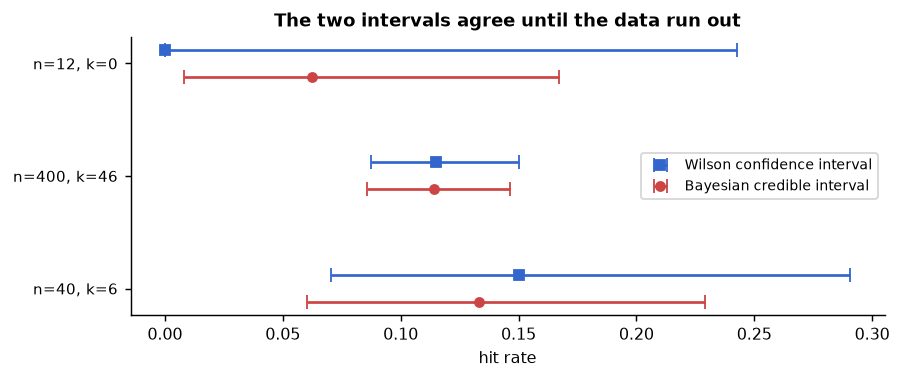

,,MLE,Wald CI,Wilson CI,Bayes mean,credible interval
n,k,,,,,
40,6,0.150,"[0.039, 0.261]","[0.071, 0.291]",0.133333,"[0.060, 0.229]"
400,46,0.115,"[0.084, 0.146]","[0.087, 0.150]",0.114286,"[0.086, 0.146]"
12,0,0.000,"[0.000, 0.000]","[0.000, 0.242]",0.062500,"[0.008, 0.167]"


In [19]:
# The two intervals on the same data, at three sample sizes, including a boundary case.
from statsmodels.stats.proportion import proportion_confint
rows = []
for n_, k_ in [(40, 6), (400, int(outcomes.sum())), (12, 0)]:
    d = stats.beta(a0 + k_, b0 + n_ - k_)
    wald = proportion_confint(k_, n_, 0.05, method="normal")
    wilson = proportion_confint(k_, n_, 0.05, method="wilson")
    rows.append({"n": n_, "k": k_, "MLE": k_ / n_,
                 "Wald CI": "[%.3f, %.3f]" % wald, "Wilson CI": "[%.3f, %.3f]" % wilson,
                 "Bayes mean": d.mean(), "credible interval": "[%.3f, %.3f]" % d.interval(0.95)})
comparison = pd.DataFrame(rows).set_index(["n", "k"])
fig, ax = plt.subplots(figsize=(7.0, 3.0))
for i, (idx, r) in enumerate(comparison.iterrows()):
    d = stats.beta(a0 + idx[1], b0 + idx[0] - idx[1])
    cw = proportion_confint(idx[1], idx[0], 0.05, method="wilson")
    ax.errorbar(r["MLE"], i + 0.12, xerr=[[r["MLE"] - cw[0]], [cw[1] - r["MLE"]]], fmt="s", ms=5,
                color="#36c", capsize=4, label="Wilson confidence interval" if i == 0 else None)
    ax.errorbar(d.mean(), i - 0.12, xerr=[[d.mean() - d.interval(0.95)[0]], [d.interval(0.95)[1] - d.mean()]],
                fmt="o", ms=5, color="#c44", capsize=4, label="Bayesian credible interval" if i == 0 else None)
ax.set_yticks(range(len(comparison)))
ax.set_yticklabels(["n=%d, k=%d" % idx for idx in comparison.index], fontsize=8.5)
ax.set_xlabel("hit rate"); ax.legend(fontsize=7.5)
ax.set_title("The two intervals agree until the data run out")
fig.tight_layout()
comparison

<p class="caption"><b>Figure 11.</b> Wilson confidence intervals (blue squares) and Bayesian credible intervals under the Beta(2,18) prior (red circles) for three datasets. At n = 400 they are indistinguishable. At n = 40 they differ by a few hundredths and tell the same story. At n = 12 with zero actives they separate decisively: the maximum-likelihood estimate is exactly 0, the naive Wald interval is the degenerate [0, 0] — a statement no one believes — and the credible interval runs from about 0.01 to 0.16, which is what a chemist would actually say after twelve failures.</p>

The boundary case in the table is the practical argument for Bayesian intervals in small-sample work. "Zero of twelve" is extremely common in early screening, in toxicity studies and in rare-event clinical data, and the classical machinery handles it badly without corrections (Wilson's interval is one such correction, and it behaves much better than Wald's). A weakly informative prior solves it by construction.

<div class="box key"><h4>Which to report</h4>
<p>Report the one whose definition matches the sentence you want to write. If the sentence is "there is a 95 % probability that the hit rate is between 6 % and 22 %", you need a credible interval, and you must state the prior. If the sentence is "a procedure with 95 % long-run coverage gives [6 %, 22 %]", a confidence interval suffices. What is never acceptable is to compute one and describe it as the other<sup class="c"><a href="#r27">[27]</a></sup>.</p></div>

## 11. Model comparison: Bayes factors and information criteria, briefly

A **Bayes factor** is the ratio of the marginal likelihoods of two models, $BF_{12}=P(D\mid M_1)/P(D\mid M_2)$: how much the data shift the relative odds of the two models<sup class="c"><a href="#r28">[28]</a></sup>. It is attractive because it can support the null hypothesis rather than merely failing to reject it<sup class="c"><a href="#r29">[29]</a></sup>, and dangerous because the marginal likelihood depends on the priors even when the posterior does not — a prior ten times too wide divides the Bayes factor by roughly ten. Computing it requires integrating over the whole prior, which is hard in more than a few dimensions.

Information criteria (AIC and BIC, Unit 9) approximate related quantities much more cheaply, and the modern Bayesian default for predictive comparison is cross-validated predictive density rather than either. For this course the practical rule is: use posterior distributions to answer questions about parameters, use cross-validation (Unit 12) to compare predictive models, and reach for Bayes factors only with explicit, justified priors and a sensitivity analysis.

In [20]:
# A Bayes factor, and how much it moves when the prior width changes.
def marginal_likelihood(a, b, n, k, grid_n=20000):
    t = np.linspace(1e-6, 1 - 1e-6, grid_n)
    return float(np.trapezoid(stats.beta(a, b).pdf(t) * stats.binom.pmf(k, n, t), t))

n_, k_ = 40, 6
m_point = stats.binom.pmf(k_, n_, 0.10)               # M2: the hit rate is exactly 10 %
for (aa, bb) in [(2, 18), (1, 9), (20, 180), (1, 1)]:
    m_flex = marginal_likelihood(aa, bb, n_, k_)      # M1: the hit rate is unknown, Beta(a,b) prior
    print("prior Beta(%5.1f,%6.1f) (prior SD %.3f) -> BF(flexible vs theta=0.10) = %.3f"
          % (aa, bb, stats.beta(aa, bb).std(), m_flex / m_point))
print("\nthe data are identical in every row; only the prior width changed.")
print("posterior means under the same four priors: %s"
      % np.round([(aa + k_) / (aa + bb + n_) for aa, bb in [(2, 18), (1, 9), (20, 180), (1, 1)]], 4))

prior Beta(  2.0,  18.0) (prior SD 0.065) -> BF(flexible vs theta=0.10) = 0.693
prior Beta(  1.0,   9.0) (prior SD 0.090) -> BF(flexible vs theta=0.10) = 0.538
prior Beta( 20.0, 180.0) (prior SD 0.021) -> BF(flexible vs theta=0.10) = 0.964
prior Beta(  1.0,   1.0) (prior SD 0.289) -> BF(flexible vs theta=0.10) = 0.228

the data are identical in every row; only the prior width changed.
posterior means under the same four priors: [0.1333 0.14   0.1083 0.1667]


The output makes the warning concrete: the four priors give posterior means spanning about 0.06 (0.108 to 0.167), yet their Bayes factors span a factor of more than four (0.23 to 0.96), because a wider prior spreads its marginal likelihood over possibilities the data rule out. Posterior summaries are robust to the prior here; the Bayes factor is not. That asymmetry is the reason this course teaches estimation rather than Bayesian hypothesis testing.

<div class="box bridge"><h4>Bridge</h4>
<p>This unit is the Bayesian counterpart of the block that preceded it: <a href="../U7_Estimation/index.html">Unit 7</a>'s confidence intervals become credible intervals in §10, <a href="../U8_Hypothesis_Testing/index.html">Unit 8</a>'s p-values become posterior probabilities in §2 and §11, and <a href="../U9_Linear_Models/index.html">Unit 9</a>'s blocking factor becomes the hierarchical model of §7 — whose frequentist sibling, <code>mixedlm</code>, is named there. Forward, the base-rate arithmetic of §2 is the foundation of <a href="../U19_Virtual_Screening/index.html">Unit 19</a>'s enrichment metrics, the partial pooling of §7 is how <a href="../U20_MD_Analytics/index.html">Unit 20</a> should combine replica averages, <a href="../U17_Uncertainty_AD/index.html">Unit 17</a> builds distribution-free prediction intervals as the non-Bayesian route to the same goal, and <a href="../U21_Omics/index.html">Unit 21</a> uses the empirical-Bayes shrinkage of gene-wise variances that §7 motivates. In the sister courses, the bioinformatics unit on <a href="../../../BGM324/03_Molecular_Docking/index.html">molecular docking</a> produces the ranked lists whose hit probability §2 computes, the cheminformatics unit on <a href="../../../Cheminformatics/U6_Databases/index.html">chemical databases</a> explains where the 108 assays of §7 come from, and the AI course's <a href="../../../BGM411/Python/index.html">probabilistic-models sessions</a> cover naive Bayes and probabilistic classifiers.</p></div>

## 12. Summary

You should be able to explain, without notes:

- Bayes' theorem in words, and why the posterior requires a prior as well as a likelihood;
- the base-rate fallacy, and why a screen with an enrichment factor of 10 on a 0.1 %-active library still delivers 99 inactive compounds in every 100 ordered;
- conjugate updating for the beta–binomial, and that the posterior mean is a weighted compromise between prior and data;
- how to compute a posterior by grid approximation, and the dimensional limit that makes it fail;
- how a Metropolis sampler works, why the normalising constant cancels, and the three diagnostics (acceptance rate, R-hat, effective sample size) that must accompany any MCMC result;
- what partial pooling does, why small groups shrink towards the grand mean and large ones do not, and which of the group's data structures are hierarchical;
- what prior and posterior predictive checks test, and why the useful test statistic is one the model was not fitted to match;
- the difference between a credible and a confidence interval, and the small-sample cases where they diverge;
- why posterior summaries are usually robust to the prior while Bayes factors are not;
- how to report a Bayesian analysis: model, priors, sampler diagnostics, posterior summaries, prior sensitivity, predictive check.

## 13. Self-assessment

<details><summary>1. A test with 99 % sensitivity and 95 % specificity is positive. Why might you still be unlikely to be ill?</summary>Because the posterior depends on the prior prevalence. With a disease frequency of 1 in 1,000, the 5 % false-positive rate applied to the 99.9 % healthy majority produces about fifty times more false positives than true positives, giving P(ill | positive) of about 2 %.</details>

<details><summary>2. Your virtual screen has EF(1 %) = 20 on a library whose prevalence of actives is 0.05 %. You order 50 compounds. How many actives do you expect?</summary>P(active | selected) ≈ 20 × 0.0005 = 0.01, so about 0.5 actives among 50 compounds. This is the arithmetic behind "order a hundred, not five", and the reason an experimental collaborator asks how many compounds the screen is confident about.</details>

<details><summary>3. Prior Beta(2,18), data 6 active of 40. What is the posterior and its mean?</summary>Beta(2+6, 18+34) = Beta(8, 52), with mean 8/60 ≈ 0.133 — between the prior mean of 0.10 and the data estimate of 0.15, closer to the data because 40 observations outweigh 20 observations' worth of prior.</details>

<details><summary>4. Why does the normalising constant not matter in the Metropolis algorithm?</summary>Because the accept/reject decision depends only on the ratio of posterior densities at two points, and the unknown constant P(D) appears in both numerator and denominator. This is what makes MCMC possible for models whose evidence integral cannot be computed.</details>

<details><summary>5. Your chain has an acceptance rate of 0.95. Is that good?</summary>No — it means the proposal steps are far too small, so the chain crawls and consecutive draws are nearly identical. The effective sample size will be tiny even though the chain is long. For a random-walk Metropolis sampler, aim for roughly 0.2–0.5 and check R-hat and ESS rather than the trace alone.</details>

<details><summary>6. What is R-hat and what value is acceptable?</summary>The ratio of an estimate of the total posterior variance (pooling chains) to the within-chain variance; if chains started from different places have converged to the same distribution it approaches 1. Values above about 1.01 indicate that the chains have not mixed, and the posterior summaries should not be used.</details>

<details><summary>7. An assay with three compounds has a mean pActivity of 8.0; the hierarchical model reports 7.7. Has the model thrown away information?</summary>No — it has combined the three measurements with the information that assays in this dataset are distributed around 6.75 with a between-assay SD of about 0.84. A mean of 8.0 from three measurements is weak evidence of an exceptional assay and strong evidence of a small sample. The shrunken estimate is the better prediction for the next compound in that assay.</details>

<details><summary>8. When does shrinkage not happen?</summary>When the group has enough data for its own mean to be precise (λ → 1 as n grows), or when the between-group variance tau is large relative to the within-group variance, meaning the groups really are different and pooling would be wrong. The model estimates tau from the data rather than assuming it, which is the point.</details>

<details><summary>9. Your posterior predictive check shows the model reproduces the mean and SD but not the kurtosis. What now?</summary>Report it, and decide whether it matters for the question. The model has parameters for the mean and the variance, so matching those is not evidence; the failure on kurtosis says the normal likelihood is wrong in the tails. If the conclusion concerns central quantities it stands; if it concerns extreme compounds, use a heavier-tailed likelihood such as Student's t.</details>

<details><summary>10. Twelve compounds tested, none active. What do you report?</summary>Not "the hit rate is 0". Report a credible interval under a stated prior — about 0.01 to 0.16 under Beta(2,18) — or a Wilson confidence interval, and state explicitly that zero of twelve is compatible with a hit rate of 10 %. The Wald interval of [0, 0] is a software artefact.</details>

<details><summary>11. Why are posterior means robust to the prior here while Bayes factors are not?</summary>Because the posterior renormalises over the parameter space and the likelihood dominates once there are enough data, whereas the marginal likelihood integrates the likelihood against the prior, so a wider prior dilutes it. A prior that barely moves a posterior mean can change a Bayes factor several-fold.</details>

<details><summary>12. A referee objects that your prior is subjective. What is the answer?</summary>That every modelling choice is, and that this one is written down. Show the prior predictive check, show the sensitivity table across several defensible priors, and show that the conclusion is unchanged — or, if it changes, say so, because then the data are not sufficient to support it without the prior.</details>

## Glossary

<dl class="gloss">
<dt>Base-rate fallacy</dt><dd>Ignoring the prior prevalence when interpreting a positive test or a predicted hit.</dd>
<dt>Bayes factor</dt><dd>Ratio of two models' marginal likelihoods; sensitive to the priors even when posteriors are not.</dd>
<dt>Conjugate prior</dt><dd>A prior whose family is preserved by the update, making the posterior available in closed form (beta–binomial, normal–normal).</dd>
<dt>Credible interval</dt><dd>An interval containing the parameter with a stated posterior probability, given data, model and prior.</dd>
<dt>Effective sample size</dt><dd>The number of independent draws an autocorrelated chain is worth.</dd>
<dt>Enrichment factor</dt><dd>Hit rate among the selected fraction divided by the library prevalence; capped at 1/prevalence.</dd>
<dt>Grid approximation</dt><dd>Evaluating prior × likelihood on a grid and normalising; exact in one or two dimensions, hopeless beyond three.</dd>
<dt>Hierarchical model</dt><dd>A model in which group parameters are themselves draws from a common distribution, producing partial pooling.</dd>
<dt>Likelihood</dt><dd>The probability of the observed data as a function of the parameters.</dd>
<dt>Marginal likelihood (evidence)</dt><dd>The probability of the data averaged over the prior; the denominator of Bayes' theorem.</dd>
<dt>MCMC</dt><dd>Markov chain Monte Carlo: a random walk whose stationary distribution is the posterior.</dd>
<dt>Metropolis algorithm</dt><dd>Propose, compute the density ratio, accept with probability min(1, r); the ancestor of all MCMC.</dd>
<dt>Non-centred parameterisation</dt><dd>Sampling a standard normal and transforming, to avoid the funnel geometry of hierarchical posteriors.</dd>
<dt>Partial pooling</dt><dd>Estimating a group parameter as a compromise between its own data and the overall distribution.</dd>
<dt>Posterior</dt><dd>The distribution of the parameters given the data; the output of a Bayesian analysis.</dd>
<dt>Posterior predictive check</dt><dd>Simulating datasets from the posterior and comparing a summary with the observed data.</dd>
<dt>Prior</dt><dd>The distribution of the parameters before seeing the data; an assumption to be stated and varied.</dd>
<dt>R-hat</dt><dd>Convergence diagnostic comparing between-chain and within-chain variance; should be below about 1.01.</dd>
<dt>Shrinkage</dt><dd>Movement of a group's estimate towards the overall mean, by an amount decreasing with the group's sample size.</dd>
<dt>Weakly informative prior</dt><dd>A prior that excludes absurd values without determining the answer; the practical default.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Harris CR, Millman KJ, van der Walt SJ, et al. Array programming with NumPy. <em>Nature</em>. 2020;585:357-362. <a href="https://doi.org/10.1038/s41586-020-2649-2">doi:10.1038/s41586-020-2649-2</a></li>
<li id="r2">Virtanen P, Gommers R, Oliphant TE, et al. SciPy 1.0: fundamental algorithms for scientific computing in Python. <em>Nat Methods</em>. 2020;17:261-272. <a href="https://doi.org/10.1038/s41592-019-0686-2">doi:10.1038/s41592-019-0686-2</a></li>
<li id="r3">Ioannidis JPA. Why most published research findings are false. <em>PLoS Med</em>. 2005;2(8):e124. <a href="https://doi.org/10.1371/journal.pmed.0020124">doi:10.1371/journal.pmed.0020124</a></li>
<li id="r4">Colquhoun D. The reproducibility of research and the misinterpretation of p-values. <em>R Soc Open Sci</em>. 2017;4:171085. <a href="https://doi.org/10.1098/rsos.171085">doi:10.1098/rsos.171085</a></li>
<li id="r5">Truchon JF, Bayly CI. Evaluating virtual screening methods: good and bad metrics for the "early recognition" problem. <em>J Chem Inf Model</em>. 2007;47(2):488-508. <a href="https://doi.org/10.1021/ci600426e">doi:10.1021/ci600426e</a></li>
<li id="r6">Mysinger MM, Carchia M, Irwin JJ, Shoichet BK. Directory of Useful Decoys, Enhanced (DUD-E): better ligands and decoys for better benchmarking. <em>J Med Chem</em>. 2012;55(14):6582-6594. <a href="https://doi.org/10.1021/jm300687e">doi:10.1021/jm300687e</a></li>
<li id="r7">Gigerenzer G, Hoffrage U. How to improve Bayesian reasoning without instruction: frequency formats. <em>Psychol Rev</em>. 1995;102(4):684-704. <a href="https://doi.org/10.1037/0033-295X.102.4.684">doi:10.1037/0033-295X.102.4.684</a></li>
<li id="r8">Casscells W, Schoenberger A, Graboys TB. Interpretation by physicians of clinical laboratory results. <em>N Engl J Med</em>. 1978;299(18):999-1001. <a href="https://doi.org/10.1056/NEJM197811022991808">doi:10.1056/NEJM197811022991808</a></li>
<li id="r9">Metropolis N, Rosenbluth AW, Rosenbluth MN, Teller AH, Teller E. Equation of state calculations by fast computing machines. <em>J Chem Phys</em>. 1953;21(6):1087-1092. <a href="https://doi.org/10.1063/1.1699114">doi:10.1063/1.1699114</a></li>
<li id="r10">Hastings WK. Monte Carlo sampling methods using Markov chains and their applications. <em>Biometrika</em>. 1970;57(1):97-109. <a href="https://doi.org/10.1093/biomet/57.1.97">doi:10.1093/biomet/57.1.97</a></li>
<li id="r11">Geman S, Geman D. Stochastic relaxation, Gibbs distributions, and the Bayesian restoration of images. <em>IEEE Trans Pattern Anal Mach Intell</em>. 1984;6(6):721-741. <a href="https://doi.org/10.1109/TPAMI.1984.4767596">doi:10.1109/TPAMI.1984.4767596</a></li>
<li id="r12">Neal RM. MCMC using Hamiltonian dynamics. In: <em>Handbook of Markov Chain Monte Carlo</em>. Chapman &amp; Hall/CRC; 2011:113-162. <a href="https://doi.org/10.1201/b10905-6">doi:10.1201/b10905-6</a></li>
<li id="r13">Gelman A, Rubin DB. Inference from iterative simulation using multiple sequences. <em>Stat Sci</em>. 1992;7(4):457-472. <a href="https://doi.org/10.1214/ss/1177011136">doi:10.1214/ss/1177011136</a></li>
<li id="r14">Vehtari A, Gelman A, Simpson D, Carpenter B, Bürkner PC. Rank-normalization, folding, and localization: an improved R-hat for assessing convergence of MCMC. <em>Bayesian Anal</em>. 2021;16(2):667-718. <a href="https://doi.org/10.1214/20-BA1221">doi:10.1214/20-BA1221</a></li>
<li id="r15">Efron B, Morris C. Stein's paradox in statistics. <em>Sci Am</em>. 1977;236(5):119-127. <a href="https://doi.org/10.1038/scientificamerican0577-119">doi:10.1038/scientificamerican0577-119</a></li>
<li id="r16">Smyth GK. Linear models and empirical Bayes methods for assessing differential expression in microarray experiments. <em>Stat Appl Genet Mol Biol</em>. 2004;3:Article 3. <a href="https://doi.org/10.2202/1544-6115.1027">doi:10.2202/1544-6115.1027</a></li>
<li id="r17">Storey JD, Tibshirani R. Statistical significance for genomewide studies. <em>Proc Natl Acad Sci USA</em>. 2003;100(16):9440-9445. <a href="https://doi.org/10.1073/pnas.1530509100">doi:10.1073/pnas.1530509100</a></li>
<li id="r18">Kalliokoski T, Kramer C, Vulpetti A, Gedeck P. Comparability of mixed IC50 data - a statistical analysis. <em>PLoS ONE</em>. 2013;8(4):e61007. <a href="https://doi.org/10.1371/journal.pone.0061007">doi:10.1371/journal.pone.0061007</a></li>
<li id="r19">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r20">Gabry J, Simpson D, Vehtari A, Betancourt M, Gelman A. Visualization in Bayesian workflow. <em>J R Stat Soc A</em>. 2019;182(2):389-402. <a href="https://doi.org/10.1111/rssa.12378">doi:10.1111/rssa.12378</a></li>
<li id="r21">Abril-Pla O, Andreani V, Carroll C, et al. PyMC: a modern, and comprehensive probabilistic programming framework in Python. <em>PeerJ Comput Sci</em>. 2023;9:e1516. <a href="https://doi.org/10.7717/peerj-cs.1516">doi:10.7717/peerj-cs.1516</a></li>
<li id="r22">Salvatier J, Wiecki TV, Fonnesbeck C. Probabilistic programming in Python using PyMC3. <em>PeerJ Comput Sci</em>. 2016;2:e55. <a href="https://doi.org/10.7717/peerj-cs.55">doi:10.7717/peerj-cs.55</a></li>
<li id="r23">Carpenter B, Gelman A, Hoffman MD, et al. Stan: a probabilistic programming language. <em>J Stat Softw</em>. 2017;76(1):1-32. <a href="https://doi.org/10.18637/jss.v076.i01">doi:10.18637/jss.v076.i01</a></li>
<li id="r24">Gelman A. Prior distributions for variance parameters in hierarchical models. <em>Bayesian Anal</em>. 2006;1(3):515-534. <a href="https://doi.org/10.1214/06-BA117A">doi:10.1214/06-BA117A</a></li>
<li id="r25">Gelman A, Jakulin A, Pittau MG, Su YS. A weakly informative default prior distribution for logistic and other regression models. <em>Ann Appl Stat</em>. 2008;2(4):1360-1383. <a href="https://doi.org/10.1214/08-AOAS191">doi:10.1214/08-AOAS191</a></li>
<li id="r26">Greenland S, Senn SJ, Rothman KJ, et al. Statistical tests, P values, confidence intervals, and power: a guide to misinterpretations. <em>Eur J Epidemiol</em>. 2016;31:337-350. <a href="https://doi.org/10.1007/s10654-016-0149-3">doi:10.1007/s10654-016-0149-3</a></li>
<li id="r27">Morey RD, Hoekstra R, Rouder JN, Lee MD, Wagenmakers EJ. The fallacy of placing confidence in confidence intervals. <em>Psychon Bull Rev</em>. 2016;23:103-123. <a href="https://doi.org/10.3758/s13423-015-0947-8">doi:10.3758/s13423-015-0947-8</a></li>
<li id="r28">Kass RE, Raftery AE. Bayes factors. <em>J Am Stat Assoc</em>. 1995;90(430):773-795. <a href="https://doi.org/10.1080/01621459.1995.10476572">doi:10.1080/01621459.1995.10476572</a></li>
<li id="r29">Wagenmakers EJ. A practical solution to the pervasive problems of p values. <em>Psychon Bull Rev</em>. 2007;14(5):779-804. <a href="https://doi.org/10.3758/BF03194105">doi:10.3758/BF03194105</a></li>
<li id="r30">Kruschke JK, Liddell TM. The Bayesian new statistics: hypothesis testing, estimation, meta-analysis, and power analysis from a Bayesian perspective. <em>Psychon Bull Rev</em>. 2018;25:178-206. <a href="https://doi.org/10.3758/s13423-016-1221-4">doi:10.3758/s13423-016-1221-4</a></li>
<li id="r31">Wasserstein RL, Lazar NA. The ASA statement on p-values: context, process, and purpose. <em>Am Stat</em>. 2016;70(2):129-133. <a href="https://doi.org/10.1080/00031305.2016.1154108">doi:10.1080/00031305.2016.1154108</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>McElreath R. <em>Statistical Rethinking</em>. 2nd ed. CRC Press; 2020. — Chapters 1–4 and 13 cover exactly this unit, with the grid-approximation-first pedagogy it follows.</li>
<li>Gelman A, Carlin JB, Stern HS, Dunson DB, Vehtari A, Rubin DB. <em>Bayesian Data Analysis</em>. 3rd ed. CRC Press; 2013 (free PDF). — Chapters 1–5 for the theory, chapter 5 for the hierarchical model of §7.</li>
<li>Kruschke JK. <em>Doing Bayesian Data Analysis</em>. 2nd ed. Academic Press; 2015. — The gentlest full-length introduction, with extensive worked code.</li>
<li>Gelman A, Hill J, Vehtari A. <em>Regression and Other Stories</em>. Cambridge University Press; 2020. — Bridges Unit 9 and this one.</li>
<li>Martin OA, Kumar R, Lao J. <em>Bayesian Modeling and Computation in Python</em>. CRC Press; 2021 (free online). — The PyMC-centred companion to §9.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>PyMC documentation and example gallery (hierarchical models, diagnostics, workflow): <a href="https://www.pymc.io/">pymc.io</a>.</li>
<li>ArviZ, the diagnostics and plotting library used with PyMC and Stan: <a href="https://python.arviz.org/">python.arviz.org</a>.</li>
<li>Stan user's guide, "Efficiency tuning" and the funnel/non-centred discussion: <a href="https://mc-stan.org/docs/">mc-stan.org/docs</a>.</li>
<li>Statistical Rethinking lecture series and code translations to PyMC: <a href="https://xcelab.net/rm/">xcelab.net/rm</a>.</li>
</ul>